![image.png](attachment:e65cf90f-046f-4bf5-bf4d-bb7aba8c3fcf.png)

**Content creator:** Babette C. Tchonang

**Content editors:** Badara Sane, Ebenzer Nyadjro, Fernand Assene, Habib Aguedjou & Nathanael Dossa

**Content coordinator:** Arielle Stela Imbol

## About this workshop

This tutorial is part of the [**OPERA Capacity Development**](https://www.unoceanprediction.org/en/ocean-prediction-enhancement-regions-africa-opera) activities, developed and led jointly by [**GGOSSS**](https://www.ggosss.org/) (Gulf of Guinea Ocean Sciences Summer School) and the [**ICMPA – UNESCO Chair**](https://www.icmpa.net/) (International Chair in Mathematical Physics and Applications).

The [OPERA project](https://www.unoceanprediction.org/en/ocean-prediction-enhancement-regions-africa-opera) (*Ocean Prediction Enhancement in Regions of Africa*) is **financed by the [European Union](https://european-union.europa.eu/)** and implemented by [**Mercator Ocean International**](https://www.mercator-ocean.eu/), in the framework of the [**Ocean Prediction Decade Collaborative Centre (OceanPrediction DCC)**](https://www.unoceanprediction.org/).

### Where Day 2 sits in the forecasting chain

```
  OBSERVE  ──►  ASSIMILATE  ──►  FORECAST  ──►  VALIDATE / USE
   Day 1          Day 2            Day 3            Day 3
  (SST, wind,   (altimetry,      (10-day          (judge it,
   currents)     the model)       forecast)        apply it)
```

On Day 1 the satellites showed us the **surface**: temperature, wind, currents. Today we use **sea level**:
the one satellite measurement that tells us about the **whole water column**, because the height of the sea surface
reflects the heat stored below it. Then we open an **ocean model** — fed with these observations — to look **beneath**.

> **Today's guiding question** — the Day 1 puzzle: *the coast of Côte d'Ivoire and Ghana cools in June–September,
> although the local Ekman transport pushes water **towards** the coast. Where does the cold water come from?*
> By 17:20 you will be able to answer it with data.

## Day 2 schedule (09:00–18:00)

| Time | Format | Activity | Region | MOOC | Notebook |
|------|--------|----------|--------|------|----------|
| 09:00–09:15 | Opening plenary | Day 1 recap, today's question | — | — | — |
| 09:15–09:45 | Subgroups | **Reconnect** — workspace, packages, login, configuration | — | — | Section 0 |
| 09:45–10:45 | Plenary demo → subgroup practice | **Altimetry as an observing system** — SLA, ADT, MDT; along-track vs gridded; **load today's data once** (runs over the break) | Shared domain | 4 | Section 1 |
| 10:45–11:05 | Break | | | | |
| 11:05–12:30 | Plenary demo → subgroup practice | **Sea level through the seasons** — daily → monthly, seasonal cycle, sea-level rise | Shared domain | 2, 4 | Section 2 |
| 12:30–13:30 | Lunch | | | | |
| 13:30–14:30 | Plenary demo → subgroup practice | **From sea level to currents** — geostrophy by hand, eddies | Shared domain | 2 | Section 3 |
| 14:30–15:00 | Plenary | **The model's sea level** — a reanalysis against the satellites | Shared domain | 3, 4 | Section 4 |
| 15:00–15:20 | Break | | | | |
| 15:20–16:20 | Plenary demo → subgroup practice | **Below the surface** — the thermocline, and the answer to the Day 1 puzzle | Shared domain | 3, 2 | Section 5 |
| 16:20–17:20 | Subgroups | **First look at your region** — one-page dashboard, a question for Day 3 | **Your area** | all | Section 6 |
| 17:20–17:50 | Reconvergence plenary | **Gallery Walk** — three regions, three questions for Day 3 | All three areas | | Discussion |
| 17:50–18:00 | Wrap-up plenary | Checklist, reflection, Day 3 preview | | | Sections 7–8 |
| *after the workshop* | On your own | **Take it home** — how to download what you used | | | Section 9 |

> **Until 16:20 everyone works the shared Gulf of Guinea domain** (`PHASE = 'shared'` in Step 0.5), so the whole room compares the same figures.
> At 16:20 each subgroup takes a first look at its own area: set `MY_AREA` in Section 6 — nothing to change above.
> **Day 3** is the day of your region: each subgroup works on it all day.

### Day 2 learning objectives

1. Explain how a satellite altimeter measures sea level, and the difference between **SLA**, **MDT** and **ADT** (Module 4).
2. Distinguish **along-track (Level 3)** observations from **gridded (Level 4)** maps (Module 4).
3. Derive monthly fields, the **seasonal cycle** and the **sea-level trend** from daily data (Modules 2, 4).
4. Compute **geostrophic currents** from sea-level gradients and explain why the method fails at the equator (Module 2).
5. Open an **ocean reanalysis**, compare it with the satellites, and use it to look **below the surface** (Modules 3, 4).

### How this notebook works

| | Everyone — instructors and participants |
|---|---|
| **All sections** | Run every cell, in order (`Shift + Enter`). **Nothing is downloaded.** |
| 🌐 | Do it in your web browser |
| 💻 | Run the code cell |
| ✍️ | Your turn |
| ✋ | Checkpoint — tell your Subgroup Instructor if it did not work |
| 🔎 | Reading a figure — what it shows and why |

## Section 0 — Reconnect

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Setup · 09:15–09:45</span>

Same workspace as Day 1 — today's figures go to `~/OPERA_Workshop/Day2/output/`.
Your Copernicus Marine login is already stored in your home folder: no password today.

In [3]:
# ============================================================
# STEP 0.1 — CREATE YOUR WORKSPACE  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# One folder per workshop day, each with an output/ subfolder.
# Same structure as Day 1: only DAY changes.
# ============================================================

from pathlib import Path
import os

DAY          = 2
WORKSHOP_DIR = Path.home() / 'OPERA_Workshop'
OUTPUT_DIR   = WORKSHOP_DIR / f'Day{DAY}' / 'output'
DATA_DIR     = WORKSHOP_DIR / 'data'          # used ONLY if you choose to download (Section 10)

for d in (1, 2, 3):
    (WORKSHOP_DIR / f'Day{d}' / 'output').mkdir(parents=True, exist_ok=True)

print('==> Workspace ready')
print(f'   Workshop folder : ~/{WORKSHOP_DIR.relative_to(Path.home())}')
print(f'   Today\'s outputs : ~/{OUTPUT_DIR.relative_to(Path.home())}')
print()
for d in (1, 2, 3):
    p = WORKSHOP_DIR / f'Day{d}' / 'output'
    n = len(list(p.glob('*')))
    mark = '   <- today' if d == DAY else ''
    print(f'   Day{d}/output   {n:>3} file(s){mark}')

==> Workspace ready
   Workshop folder : ~/OPERA_Workshop
   Today's outputs : ~/OPERA_Workshop/Day2/output

   Day1/output    16 file(s)
   Day2/output     7 file(s)   <- today
   Day3/output     0 file(s)


In [4]:
# ============================================================
# STEP 0.2 — CHECK & INSTALL PACKAGES  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Installs what is missing into your HOME folder (kept when the
# hub server restarts), then VERIFIES with a fresh Python what
# the kernel will load after the restart.
# ============================================================

import importlib, importlib.metadata, subprocess, sys

REQUIRED = [  # (import name, pip requirement)
    ('copernicusmarine', 'copernicusmarine'),
    ('xarray',           'xarray'),
    ('dask',             'dask'),
    ('zarr',             'zarr>=3'),
    ('aiohttp',          'aiohttp'),
    ('netCDF4',          'netCDF4'),
    ('h5netcdf',         'h5netcdf'),
    ('numpy',            'numpy'),
    ('pandas',           'pandas'),
    ('scipy',            'scipy'),
    ('matplotlib',       'matplotlib'),
    ('cartopy',          'cartopy'),
    ('cmocean',          'cmocean'),
]

def fresh_versions(names):
    """Ask a NEW Python process (= the kernel after a restart) which versions it loads."""
    code = ('import importlib, json\nout = {}\n'
            f'for n in {names!r}:\n'
            '    try:\n'
            '        m = importlib.import_module(n); out[n] = [getattr(m, "__version__", "?"), getattr(m, "__file__", "?")]\n'
            '    except Exception as e:\n'
            '        out[n] = ["MISSING", type(e).__name__]\n'
            'print(json.dumps(out))')
    r = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True)
    import json
    return json.loads(r.stdout.strip().splitlines()[-1])

print(f' Python: {sys.executable}\n')
print(' Checking packages...\n')
missing = []
for import_name, requirement in REQUIRED:
    try:
        importlib.import_module(import_name)
        version = importlib.metadata.version(requirement.split('>')[0].split('=')[0])
        if import_name == 'zarr' and int(version.split('.')[0]) < 3:
            print(f'  !!   zarr {version:<12} version 3 or newer is needed to stream the data — will be updated')
            missing.append(requirement)
        else:
            print(f'  ==>  {import_name:<17} {version}')
    except ImportError:
        print(f'  ..   {import_name:<17} not installed yet — will be installed')
        missing.append(requirement)

if not missing:
    print('\n All packages ready — proceed to Step 0.3')
else:
    print(f'\n Installing: {", ".join(missing)} (1–3 minutes)...')
    # --user installs into your HOME folder, which survives a server restart
    # (the system environment is reset each time the hub server starts).
    result = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', '--user', *missing],
                            capture_output=True, text=True)
    if result.returncode != 0:      # fallback: environments that refuse --user
        result = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', *missing],
                                capture_output=True, text=True)
    if result.returncode != 0:
        print(' ❌  Installation failed — show this message to your Subgroup Instructor:\n')
        print(result.stderr[-1500:])
    else:
        if 'kerchunk' in result.stderr:
            print('      (pip mentions "kerchunk requires zarr<3": harmless — kerchunk is not used in this workshop.)')
        # verify what the kernel WILL load after a restart
        check = fresh_versions([n for n, _ in REQUIRED])
        zv, zfile = check['zarr']
        problems = [n for n, (v, _) in check.items() if v == 'MISSING']
        if zv != 'MISSING' and int(str(zv).split('.')[0]) < 3:
            problems.append(f'zarr is still {zv} ({zfile})')
        if problems:
            print(' ❌  Installed, but a fresh Python still sees a problem:')
            for p in problems:
                print('       -', p)
            print('     Show this to your Subgroup Instructor.')
        else:
            print(f' ==>  Installation verified (zarr {zv}  ->  {zfile})')
            print('\n==>  RESTART REQUIRED: Kernel -> Restart Kernel, then re-run Steps 0.1 and 0.2')

 Python: /srv/conda/envs/notebook/bin/python

 Checking packages...

  ==>  copernicusmarine  2.5.0
  ==>  xarray            2026.7.0
  ==>  dask              2026.8.0
  ==>  zarr              3.4.2
  ==>  aiohttp           3.14.3
  ==>  netCDF4           1.7.4
  ==>  h5netcdf          1.8.1
  ==>  numpy             2.5.2
  ==>  pandas            2.3.3
  ==>  scipy             1.18.0
  ==>  matplotlib        3.11.1
  ==>  cartopy           0.25.0
  ==>  cmocean           4.0.3

 All packages ready — proceed to Step 0.3


In [5]:
# ============================================================
# STEP 0.3 — IMPORT ALL LIBRARIES  (Everyone runs this)
# ============================================================

import time, shutil, warnings, logging
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import dask
import copernicusmarine
from dask.diagnostics import ProgressBar
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
logging.getLogger('copernicusmarine').setLevel(logging.WARNING)   # hide the Toolbox INFO messages
PC = ccrs.PlateCarree()

plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'font.size': 10,
                     'axes.titley': 1.02})   # fixed title position: avoids a matplotlib 3.11 + cartopy bug
                                             # that makes maps with gridline labels disappear

# Guard: the kernel must have been restarted after Step 0.2 installed zarr 3
import zarr
if int(zarr.__version__.split('.')[0]) < 3:
    raise RuntimeError(f'zarr {zarr.__version__} is still loaded in this session. '
                       'Kernel -> Restart Kernel, then re-run the notebook from the top (Steps 0.1, 0.2, 0.3...).')

print('==> Libraries imported:')
print(f'   xarray           {xr.__version__}')
print(f'   numpy            {np.__version__}')
print(f'   zarr             {zarr.__version__}')
print(f'   copernicusmarine {copernicusmarine.__version__}')

==> Libraries imported:
   xarray           2026.7.0
   numpy            2.5.2
   zarr             3.4.2
   copernicusmarine 2.5.0


In [6]:
# ============================================================
# STEP 0.4 — HELPERS  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# The Day 1 helpers, plus nearest_ocean(): coastal places sit on
# land, so a time series must be taken at the nearest OCEAN point.
# ============================================================

def decorate(ax, extent=None, left=True, bottom=True, land='#C8B99A'):
    """Land, coastline, borders, gridlines — the same style on every map."""
    ax.add_feature(cfeature.LAND,      color=land, zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.9, edgecolor='black', zorder=3)
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', edgecolor='gray', zorder=3)
    if extent is not None:
        ax.set_extent(extent, crs=PC)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False
    gl.left_labels, gl.bottom_labels = left, bottom
    return gl


def save_fig(fig, name):
    """Save a figure in today's output folder and say where it went."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'==> Saved: ~/{path.relative_to(Path.home())}')
    return path


def robust_range(da, low=2, high=98, step=0.5):
    """Colour range from the 2nd-98th percentiles, rounded — works for any region."""
    lo, hi = np.nanpercentile(np.asarray(da), [low, high])
    return np.floor(lo / step) * step, np.ceil(hi / step) * step


def arrows(ax, u, v, n_across=20, scale=120, key=5, key_label='5 m s$^{-1}$',
           key_xy=(0.05, 0.05), width=0.0035, color='black'):
    """Quiver plot thinned to ~n_across arrows, with a reference arrow (inside the map)."""
    step = max(1, u.sizes['longitude'] // n_across)
    uq = u.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    vq = v.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    q = ax.quiver(uq.longitude.values, uq.latitude.values, uq.values, vq.values,
                  transform=PC, scale=scale, width=width, color=color, alpha=0.8, zorder=4)
    ax.quiverkey(q, *key_xy, key, key_label, labelpos='E', coordinates='axes',
                 fontproperties={'size': 9})
    return q


def nearest_ocean(field2d, lon, lat):
    """Longitude and latitude of the ocean grid point closest to (lon, lat)."""
    f = field2d.reset_coords(drop=True)
    dist = ((f.longitude - lon) ** 2 + (f.latitude - lat) ** 2).where(f.notnull())
    idx = dist.fillna(1e9).argmin(dim=['latitude', 'longitude'])
    return float(f.longitude[idx['longitude']]), float(f.latitude[idx['latitude']])

def nearest_deep_point(lon, lat, depth, date):
    """Model ocean point closest to (lon, lat) where the sea is at least `depth` m deep.

    On the continental shelf the sea can be only a few tens of metres deep: a
    temperature profile there stops at the sea floor, and the thermocline may be
    'below the bottom'. We read ONE day of model temperature at ~`depth` m in a
    2° x 2° box (NaN where the sea is shallower) and take the nearest valid point.
    """
    t = stream('MODEL', start=date, end=date, service='arco-geo-series', variables=['thetao'],
               box=dict(minimum_longitude=lon - 1, maximum_longitude=lon + 1,
                        minimum_latitude=lat - 1,  maximum_latitude=lat + 1),
               minimum_depth=0.8 * depth, maximum_depth=depth)['thetao']
    return nearest_ocean(t.isel(time=0, depth=-1).compute(), lon, lat)

print('==> Helpers ready: decorate(), save_fig(), robust_range(), arrows(), nearest_ocean(), nearest_deep_point()')

==> Helpers ready: decorate(), save_fig(), robust_range(), arrows(), nearest_ocean(), nearest_deep_point()


### Step 0.5 — Configuration

Same configuration as Day 1, with two additions for today: a **coastal point** (where we look below the surface)
and a **section** (a vertical slice through the ocean). The study areas have been **checked against the coastline**:
Area 2 now covers the Bights of Benin and Biafra, the Niger Delta and the Gabon coast; Area 3 now includes the
Agulhas Current along the east coast and its **retroflection** south of Africa.

**Today everyone works the shared domain** (`PHASE = 'shared'`). In Section 6 each subgroup takes a first look at its own area — directly in that cell, without coming back here.

In [7]:
# ============================================================
# STEP 0.5 — TWO-PHASE DOMAIN CONFIGURATION
# ─────────────────────────────────────────────────────────────
# PHASE 'shared' — everyone works the Gulf of Guinea domain
# PHASE 'zone'   — the whole notebook for one area (optional, after the workshop)
# New today: COAST_POINT (below-surface time series) and SECTION
# (vertical slice through the ocean, Section 5).
# ============================================================

SHARED = dict(
    name        = 'Gulf of Guinea (shared domain)',
    prefix      = 'GOG',
    lon         = (-10.0, 15.0),
    lat         = (-10.0, 10.0),
    ref_points  = [(-3.5, 5.0, 'Abidjan / Accra'), (2.5, 6.0, 'Cotonou'), (9.5, 1.0, 'Port-Gentil')],
    coast_point = (-1.5, 4.6, 'off Cape Three Points (Ghana)'),
    section     = dict(kind='meridional', lon=-1.0, lat=(-10.0, 5.5),
                       label='1°W — from the Ghana coast to 10°S'),
    isotherm    = 20.0, section_depth = 300, profile_depth = 200,
)

ZONES = {
    '1': dict(
        name        = 'Mauritania / Senegal',
        prefix      = 'MRS',
        lon         = (-21.0, -15.0),
        lat         = ( 14.0,  25.0),
        regime      = 'Canary Eastern Boundary Upwelling System',
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [(-17.3, 21.0, 'Nouadhibou  (Mauritania)'),
                       (-16.4, 18.1, 'Nouakchott  (Mauritania)'),
                       (-17.6, 14.7, 'Dakar  (Senegal)')],
        coast_point = (-17.6, 20.0, 'off Cap Blanc'),
        section     = dict(kind='zonal', lat=20.0, lon=(-21.0, -16.3),
                           label='20°N — offshore to the Mauritanian coast'),
        isotherm    = 15.0, section_depth = 300, profile_depth = 200,   # surface water drops below 20 °C in winter
    ),
    '2': dict(
        name        = 'Gulf of Guinea — eastern part',
        prefix      = 'GGE',
        lon         = (  2.0, 12.0),
        lat         = ( -5.0,  6.5),
        regime      = 'Equatorial / monsoon, large river outflow',
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [( 6.0,  3.5, 'Bight of Biafra'),
                       ( 8.5, -0.7, 'Port-Gentil  (Gabon)'),
                       (11.3, -4.8, 'Pointe-Noire  (Congo)')],
        coast_point = ( 8.5, -0.8, 'off Port-Gentil'),
        section     = dict(kind='meridional', lon=6.0, lat=(-5.0, 4.3),
                           label='6°E — from the Niger Delta across the equator'),
        isotherm    = 20.0, section_depth = 300, profile_depth = 200,
    ),
    '3': dict(
        name        = 'Agulhas',
        prefix      = 'AGU',
        lon         = ( 15.0,  32.0),
        lat         = (-41.0, -30.0),
        regime      = 'Western boundary current — rings, eddies, marine heatwaves',
        hemisphere  = 'S', upwell_season = 'DJF',
        ref_points  = [(18.2, -34.6, 'Cape Point  (South Africa)'),
                       (22.2, -34.6, 'Mossel Bay  (South Africa)'),
                       (28.5, -33.5, 'East London  (South Africa)')],
        coast_point = (28.5, -33.5, 'Agulhas Current, off East London'),
        section     = dict(kind='meridional', lon=25.0, lat=(-41.0, -34.2),
                           label='25°E — across the Agulhas retroflection'),
        isotherm    = 15.0, section_depth = 800, profile_depth = 500,   # a deep, warm current
    ),
}

PHASE       = 'shared'     # <- keep 'shared' today (Section 6 has its own area setting)
ACTIVE_ZONE = '2'          # <- '1', '2' or '3'

Z = ZONES[ACTIVE_ZONE]
D = SHARED if PHASE == 'shared' else Z

LON_MIN, LON_MAX = D['lon']
LAT_MIN, LAT_MAX = D['lat']
DOMAIN_NAME  = D['name']
FILE_PREFIX  = D['prefix']
REF_POINTS   = D['ref_points']
COAST_POINT  = D['coast_point']
SECTION      = D['section']
ISOTHERM     = D['isotherm']        # the isotherm that marks the thermocline (°C)
SECTION_DEPTH, PROFILE_DEPTH = D['section_depth'], D['profile_depth']
HEMISPHERE   = 'N' if PHASE == 'shared' else Z['hemisphere']
EXTENT       = [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX]

BOX = dict(minimum_longitude=LON_MIN, maximum_longitude=LON_MAX,
           minimum_latitude=LAT_MIN,  maximum_latitude=LAT_MAX)

DATE_START = '1993-01-01'
DATE_END   = '2025-12-31'
LIGHT_MODE = False          # True = 2020-2025 only (slow connection)
if LIGHT_MODE:
    DATE_START = '2010-01-01'
PERIOD = f'{DATE_START[:4]}–{DATE_END[:4]}'

SNAP_DATE   = '2019-08-15'                       # a day in the boreal upwelling season
TRACK_START, TRACK_END = '2019-08-01', '2019-08-28'   # along-track window (Sentinel-3A repeats its tracks every 27 days)
EKE_START   = '2023-01-01'                       # eddy statistics over the last 3 years
HOV_START, HOV_END = '2018-01-01', '2019-12-31'  # below-surface time series (2 years)
EQUATOR_MASK_DEG = 2.0                           # geostrophy is not computed within ±2° of the equator

COLORS = ['#E74C3C', '#27AE60', '#8E44AD']

print(f'==> PHASE = {PHASE.upper()}  —  {DOMAIN_NAME}')
print(f'   Box          : lon [{LON_MIN}, {LON_MAX}]   lat [{LAT_MIN}, {LAT_MAX}]')
print(f'   Period       : {DATE_START} -> {DATE_END}' + ('   (LIGHT_MODE)' if LIGHT_MODE else ''))
print(f'   Snapshot day : {SNAP_DATE}')
print(f'   Coastal point: {COAST_POINT[2]}  ({COAST_POINT[0]}°, {COAST_POINT[1]}°)')
print(f'   Section      : {SECTION["label"]}  (0–{SECTION_DEPTH} m)')
print(f'   Thermocline  : depth of the {ISOTHERM:.0f} °C isotherm')
if HEMISPHERE == 'S':
    print('\n   !! SOUTHERN HEMISPHERE — seasons are reversed: JJA is WINTER, DJF is SUMMER.')

==> PHASE = SHARED  —  Gulf of Guinea (shared domain)
   Box          : lon [-10.0, 15.0]   lat [-10.0, 10.0]
   Period       : 1993-01-01 -> 2025-12-31
   Snapshot day : 2019-08-15
   Coastal point: off Cape Three Points (Ghana)  (-1.5°, 4.6°)
   Section      : 1°W — from the Ghana coast to 10°S  (0–300 m)
   Thermocline  : depth of the 20 °C isotherm


In [8]:
# ============================================================
# STEP 0.6 — LOGIN CHECK  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Credentials were stored on Day 1. Only if they are missing
# will you be asked for them again.
# ============================================================

from getpass import getpass

if copernicusmarine.login(check_credentials_valid=True):
    print('==> Copernicus Marine credentials found and valid — nothing to do.')
else:
    print('No valid credentials found. Enter your Copernicus Marine username and password.')
    username = input('Copernicus Marine username: ').strip()
    password = getpass('Copernicus Marine password: ')
    copernicusmarine.login(username=username, password=password, force_overwrite=True)
    del password
    print('==> Logged in.' if copernicusmarine.login(check_credentials_valid=True)
          else '==> Login did NOT verify — check your username / password.')

==> Copernicus Marine credentials found and valid — nothing to do.


In [9]:
# ============================================================
# STEP 0.7 — TODAY'S DATASETS  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Two families: OBSERVATIONS (satellite altimetry) and a MODEL
# (the GLORYS12 ocean reanalysis). All global, all streamed.
# ============================================================

DATASETS = {
    'SSH':  dict(product   = 'SEALEVEL_GLO_PHY_L4_MY_008_047',
                 dataset_id= 'cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D',
                 variables = ['sla', 'adt', 'ugos', 'vgos', 'ugosa', 'vgosa'],
                 label     = 'Sea level, gridded Level 4 — DUACS, all satellites, daily, 0.125°'),
    'S3A':  dict(product   = 'SEALEVEL_GLO_PHY_L3_MY_008_062',
                 dataset_id= 'cmems_obs-sl_glo_phy-ssh_my_s3a-l3-duacs_PT1S',
                 variables = ['sla_filtered', 'mdt'],
                 label     = 'Sea level, along-track Level 3 — Sentinel-3A, 1 Hz'),
    'MODEL':  dict(product = 'GLOBAL_MULTIYEAR_PHY_001_030',
                 dataset_id= 'cmems_mod_glo_phy_my_0.083deg_P1D-m',
                 variables = ['zos', 'thetao', 'mlotst'],
                 label     = 'GLORYS12 ocean reanalysis — daily, 1/12°, 50 levels'),
    'MODEL_M': dict(product= 'GLOBAL_MULTIYEAR_PHY_001_030',
                 dataset_id= 'cmems_mod_glo_phy_my_0.083deg_P1M-m',
                 variables = ['thetao'],
                 label     = 'GLORYS12 ocean reanalysis — monthly means (for the 3-D section)'),
}

rows = []
for key, spec in DATASETS.items():
    try:
        copernicusmarine.describe(dataset_id=spec['dataset_id'], disable_progress_bar=True)
        ok = '✅'
    except Exception as e:
        ok = f'❌ {type(e).__name__}'
    rows.append({'use': key, 'what': spec['label'], 'dataset_id': spec['dataset_id'], 'in catalogue': ok})
display(pd.DataFrame(rows).set_index('use'))


def stream(kind, start=None, end=None, service=None, box=None, **extra):
    """Open one Copernicus Marine dataset lazily (default: active BOX and full period)."""
    spec = DATASETS[kind]
    return copernicusmarine.open_dataset(
        dataset_id     = spec['dataset_id'],
        variables      = extra.pop('variables', spec['variables']),
        start_datetime = f'{start or DATE_START}T00:00:00',
        end_datetime   = f'{end or DATE_END}T23:59:59',
        service        = service,
        **(box or BOX), **extra)

,what,dataset_id,in catalogue
use,,,
SSH,"Sea level, gridded Level 4 — DUACS, all satell...",cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0....,✅
S3A,"Sea level, along-track Level 3 — Sentinel-3A, ...",cmems_obs-sl_glo_phy-ssh_my_s3a-l3-duacs_PT1S,✅
MODEL,"GLORYS12 ocean reanalysis — daily, 1/12°, 50 l...",cmems_mod_glo_phy_my_0.083deg_P1D-m,✅
MODEL_M,GLORYS12 ocean reanalysis — monthly means (for...,cmems_mod_glo_phy_my_0.083deg_P1M-m,✅


## Section 1 — Altimetry as an Observing System

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Observation block · 09:45–10:45</span> &nbsp; **MOOC Module 4 — Ocean observations**

### How a satellite measures sea level

A radar **altimeter** sends a pulse straight down and times its echo. Knowing the satellite's orbit to within a few
centimetres, the travel time gives the **height of the sea surface** — along a narrow **ground track** under the satellite.

```
     satellite orbit (known to ~1–2 cm)
            │  radar pulse down and back:  range = c × t / 2
            ▼
   ~~~~~~~~ sea surface ~~~~~~~~~~~~~~~~~~~~~   ← SSH  = orbit altitude − range
   - - - - - geoid (level surface of gravity) - - -
```
Three quantities, one equation — **memorise this one**:

| Quantity | Meaning | Changes with time? |
|---|---|---|
| **MDT** — Mean Dynamic Topography | the **mean** height of the sea surface above the geoid (here: the 1993–2012 average) | No |
| **SLA** — Sea Level Anomaly | the **departure** from that mean on a given day | Yes |
| **ADT** — Absolute Dynamic Topography | the **total** dynamic height on a given day | Yes |

$$ \mathrm{ADT} = \mathrm{MDT} + \mathrm{SLA} $$

- **SLA** shows what is *unusual*: eddies, waves, seasonal and interannual changes, sea-level rise.
- **ADT** is what drives the **absolute geostrophic currents** (Section 3): water flows *along* ADT contours.

### Why sea level matters below the surface

Warm water is lighter and takes more room. When the warm upper layer is **thick** (the thermocline is deep), the sea
surface stands **higher**; when cold water rises towards the surface (the thermocline is shallow), the surface **drops** —
by a few centimetres. **A satellite measuring centimetres at the surface tells us about the ocean hundreds of metres below.**

In [10]:
# ============================================================
# STEP 1.1 — OPEN THE DAILY GRIDDED SEA LEVEL (no download)
# ─────────────────────────────────────────────────────────────
# Two layouts of the same data, as on Day 1:
#   geo-series  -> maps of one day
#   time-series -> long series and multi-year statistics
# ============================================================

t0 = time.time()
ds_ssh    = stream('SSH', service='arco-geo-series')
ds_ssh_ts = stream('SSH', service='arco-time-series')
print(f'==> Sea level opened in {time.time() - t0:.1f} s — no data transferred yet')
print(f'   {ds_ssh.sizes["time"]} daily fields x {ds_ssh.sizes["latitude"]} x {ds_ssh.sizes["longitude"]}'
      f'   [{", ".join(str(v) for v in ds_ssh.data_vars)}]   {ds_ssh.nbytes / 1e9:.1f} GB if downloaded')
print(f'   Days available: {str(ds_ssh.time.values[0])[:10]} -> {str(ds_ssh.time.values[-1])[:10]}')

==> Sea level opened in 10.7 s — no data transferred yet
   12053 daily fields x 160 x 200   [sla, adt, ugos, vgos, ugosa, vgosa]   18.5 GB if downloaded
   Days available: 1993-01-01 -> 2025-12-31


==> Saved: ~/OPERA_Workshop/Day2/output/Day2_SLA_MDT_ADT_GOG.png


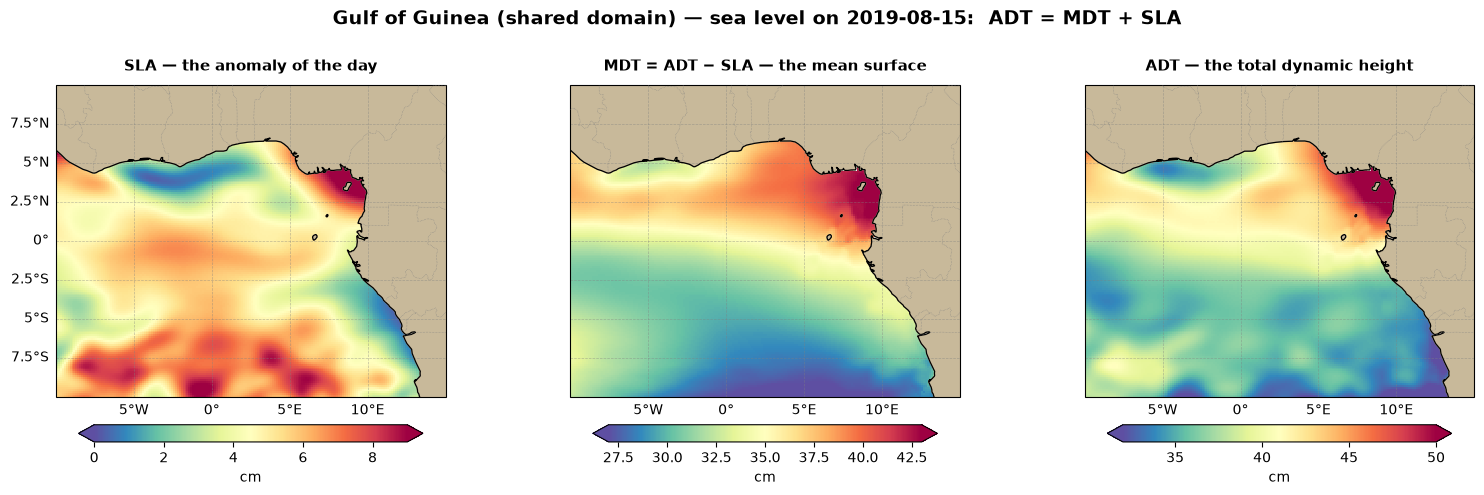

   Check of the equation at the domain mean: MDT 33.0 + SLA 5.1 = 38.1 cm   vs   ADT 38.1 cm


In [11]:
# ============================================================
# STEP 1.2 — SLA, MDT AND ADT ON ONE DAY
# ─────────────────────────────────────────────────────────────
# MDT is not in the daily dataset: we RECOVER it from the
# equation ADT = MDT + SLA  ->  MDT = ADT − SLA.
# Only this one day is transferred.
# ============================================================

day = ds_ssh[['sla', 'adt']].sel(time=SNAP_DATE, method='nearest').compute()
sla_day = 100 * day['sla']                     # cm
adt_day = 100 * day['adt']
mdt     = adt_day - sla_day                    # the time-independent mean surface

fig, axes = plt.subplots(1, 3, figsize=(16, 5.4), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.04, right=0.97, top=0.82, bottom=0.08, wspace=0.12)
panels = [(sla_day, 'SLA — the anomaly of the day', 'Spectral_r', False),
          (mdt,     'MDT = ADT − SLA — the mean surface', 'Spectral_r', False),
          (adt_day, 'ADT — the total dynamic height', 'Spectral_r', False)]
for ax, (field, title, cmap, symmetric) in zip(axes, panels):
    lo, hi = robust_range(field, step=1)
    if symmetric:
        lim = max(abs(lo), abs(hi)); lo, hi = -lim, lim
    p = field.plot(ax=ax, transform=PC, cmap=cmap, vmin=lo, vmax=hi, add_labels=False,
                   cbar_kwargs={'label': 'cm', 'shrink': 0.75, 'extend':'both','orientation': 'horizontal', 'pad': 0.07})
    decorate(ax, extent=EXTENT, left=(ax is axes[0]))
    ax.set_title(title, fontsize=11)
fig.suptitle(f'{DOMAIN_NAME} — sea level on {str(day.time.values)[:10]}:  ADT = MDT + SLA',
             fontsize=14, fontweight='bold', y=0.96)
save_fig(fig, f'Day2_SLA_MDT_ADT_{FILE_PREFIX}.png')
plt.show()

print(f'   Check of the equation at the domain mean: MDT {float(mdt.mean()):.1f} + SLA {float(sla_day.mean()):.1f}'
      f' = {float(mdt.mean() + sla_day.mean()):.1f} cm   vs   ADT {float(adt_day.mean()):.1f} cm')

### 🔎 Reading the three maps

- **MDT** is smooth and large-scale: it is the *permanent* shape of the sea surface, set by the mean currents.
  Its gradients drive the mean circulation (the Guinea Current, the equatorial currents).
- **SLA** is patchy and small: today's eddies, waves and seasonal departures. Positive = higher than usual.
- **ADT** looks almost like MDT — because the anomaly is only a few centimetres on top of a mean that varies by tens of centimetres.

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (3 min)</b><br>Change <code>SNAP_DATE</code> in Step 0.5 to a day in <b>March</b> (e.g. <code>'2019-03-15'</code>), re-run Steps 0.5 and 1.2. Which map changes, and which does not? Why?</div>

### 1.3 — Along-track (Level 3) vs gridded (Level 4)

The smooth maps above are **Level 4**: several satellites' tracks blended and **interpolated** onto a grid.
What a satellite **actually measures** is **Level 3**: one value every ~7 km **along its track**, nothing in between.
Let us look at ten days of **Sentinel-3A** over the same box.

Along-track data are *points*, not a grid, so the Toolbox reads them with `read_dataframe()` (a table), which we turn back into `xarray`.

100%|██████████| [00:10<00:00]


==> 11,673 along-track measurements in 2019-08-01 → 2019-08-28
==> Saved: ~/OPERA_Workshop/Day2/output/Day2_L3_vs_L4_GOG.png


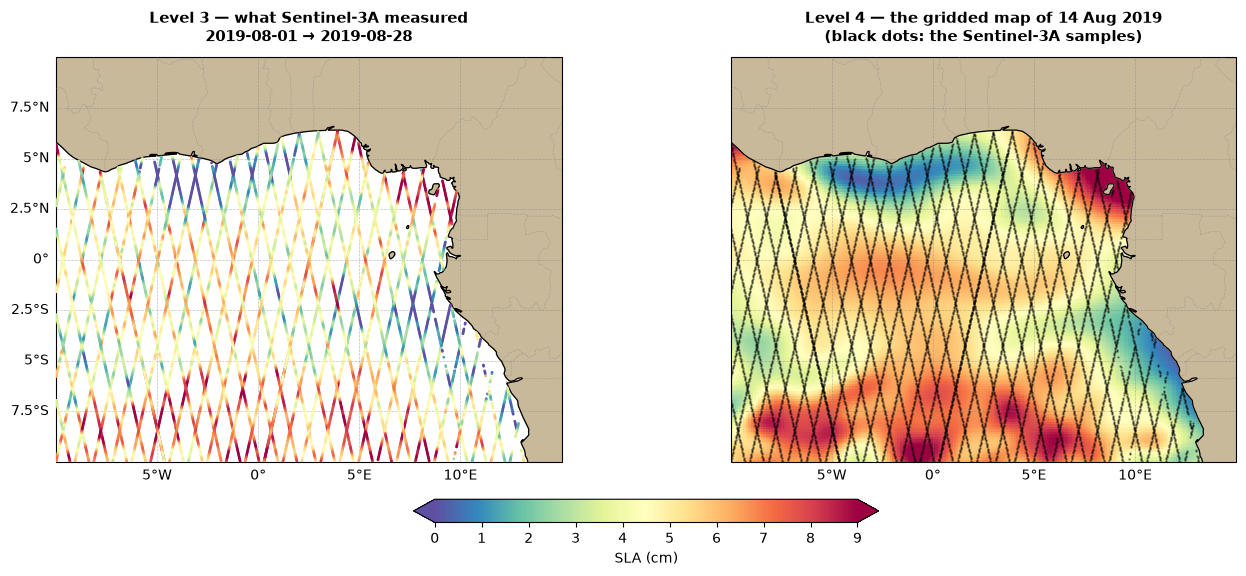

In [12]:
# ============================================================
# STEP 1.3 — TEN DAYS OF SENTINEL-3A ALONG-TRACK DATA (Level 3)
# ============================================================

df = copernicusmarine.read_dataframe(
    dataset_id=DATASETS['S3A']['dataset_id'], variables=DATASETS['S3A']['variables'],
    start_datetime=f'{TRACK_START}T00:00:00', end_datetime=f'{TRACK_END}T23:59:59', **BOX)
df = df.reset_index() if 'time' not in df.columns else df
if {'variable', 'value'}.issubset(df.columns):                    # "long" table -> one column per variable
    df = (df.pivot_table(index=['time', 'longitude', 'latitude'], columns='variable',
                         values='value', aggfunc='first').reset_index())
    df.columns.name = None
df['longitude'] = np.where(df['longitude'] > 180, df['longitude'] - 360, df['longitude'])
tracks = df.dropna(subset=['sla_filtered'])
print(f'==> {len(tracks):,} along-track measurements in {TRACK_START} → {TRACK_END}')

mid = pd.Timestamp(TRACK_START) + (pd.Timestamp(TRACK_END) - pd.Timestamp(TRACK_START)) / 2
l4_mid = 100 * ds_ssh['sla'].sel(time=mid, method='nearest').compute()
lim = max(abs(np.array(robust_range(l4_mid, step=1))))
limin, limax = robust_range(l4_mid, step=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.05, right=0.97, top=0.85, bottom=0.10, wspace=0.10)
sc = axes[0].scatter(tracks['longitude'], tracks['latitude'], c=100 * tracks['sla_filtered'], s=4, linewidths=0,
                     cmap='Spectral_r', vmin=limin, vmax=limax, transform=PC, zorder=4)
decorate(axes[0], extent=EXTENT)
axes[0].set_title(f'Level 3 — what Sentinel-3A measured\n{TRACK_START} → {TRACK_END}', fontsize=11)
p = l4_mid.plot(ax=axes[1], transform=PC, cmap='Spectral_r', vmin=limin, vmax=limax, add_colorbar=False, add_labels=False)
axes[1].scatter(tracks['longitude'], tracks['latitude'], s=0.5, color='k', alpha=0.4, transform=PC, zorder=4)
decorate(axes[1], extent=EXTENT, left=False)
axes[1].set_title(f'Level 4 — the gridded map of {mid:%d %b %Y}\n(black dots: the Sentinel-3A samples)', fontsize=11)
fig.colorbar(sc, ax=axes, orientation='horizontal', fraction=0.05, pad=0.08, extend='both', label='SLA (cm)')
save_fig(fig, f'Day2_L3_vs_L4_{FILE_PREFIX}.png')
plt.show()

### 🔎 Reading Level 3 vs Level 4

- One satellite in ten days leaves **wide gaps** between tracks. Sentinel-3A repeats its pattern every **27 days**, when its tracks are ~100 km apart at the equator; in ten days only about a third of them have been flown.
- The Level 4 map fills those gaps by combining **all available altimeters** (typically 4–7) and **interpolating** in space and time.
  It is complete, but **smoother**: features smaller than ~100–150 km and a few days are not resolved.
- Near the **coast** (last ~20 km), altimetry is less reliable: the radar echo is contaminated by land.

> **MOOC Module 4 link:** this is the observing system that feeds the models. On Day 3, the forecasts you open
> were started from analyses that **assimilated** exactly these along-track measurements.

### 1.4 — Load today's data once

As on Day 1 (Step 4.5b), the rest of the day needs **many years of daily data**. Instead of streaming in every section,
we stream it **once**, reduce it to what we need, and keep the result in memory:

| What | Streamed as | Kept as | Used in |
|---|---|---|---|
| Sea level anomaly | daily maps | **monthly** maps (`resample`) | Section 2 |
| Current anomalies | daily maps | one map of eddy energy | Section 3 |
| Sea level at the 3 places | daily, satellites **and** model | **monthly** series | Section 4 |
| Model temperature section | monthly, 3-D | March and August means | Section 5 |
| The coastal point | daily, model profiles **and** satellites | two years, daily | Section 5 |

**One progress bar for the whole day.** After this cell, Sections 2–5 run in seconds.

<div style="border-left:6px solid #009E8A; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#009E8A"> Start it before the break</b><br>Run Step 1.4 just before the 10:45 break and let it work while you are away. If you come back and it is still running, read Section 2 while it finishes.</div>

In [13]:
# ============================================================
# STEP 1.4 — LOAD TODAY'S DATA ONCE  (the only long step today)
# ─────────────────────────────────────────────────────────────
# As on Day 1 (Step 4.5b): build the whole "recipe" lazily,
# then stream + reduce everything in ONE dask.compute().
#
#   what                       streamed as        kept as
#   sea level anomaly          daily maps         monthly maps      -> Section 2
#   current anomalies          daily maps         eddy energy map   -> Section 3
#   sea level at 3 places      daily (sat+model)  monthly series    -> Section 4
#   temperature section        monthly (model)    March & August    -> Section 5
#   coastal point              daily (model+sat)  2 years, daily    -> Section 5
# ============================================================

# --- one day of each field: tells us where the ocean is (small) ---
ds_model    = stream('MODEL', service='arco-geo-series',  variables=['zos'])
ds_model_ts = stream('MODEL', service='arco-time-series', variables=['zos'])
zos_day = (100 * ds_model['zos'].sel(time=SNAP_DATE, method='nearest')).compute()
adt_obs = (100 * ds_ssh['adt'].sel(time=SNAP_DATE, method='nearest')).compute()

# --- the places: nearest MODEL ocean point to each reference place ---
POINTS = [(name.split('(')[0].strip(), *nearest_ocean(zos_day, lon, lat)) for lon, lat, name in REF_POINTS]

# --- the coastal point: the nearest model point DEEP enough for the whole profile (0–PROFILE_DEPTH m).
#     On the shelf the sea is too shallow: the isotherm would often be below the sea floor.
clon, clat, cname = COAST_POINT
plon, plat = nearest_deep_point(clon, clat, PROFILE_DEPTH, SNAP_DATE)

# --- the section line ---
if SECTION['kind'] == 'meridional':
    sbox = dict(minimum_longitude=SECTION['lon'] - 0.05, maximum_longitude=SECTION['lon'] + 0.05,
                minimum_latitude=SECTION['lat'][0], maximum_latitude=SECTION['lat'][1])
    along = 'latitude'
else:
    sbox = dict(minimum_longitude=SECTION['lon'][0], maximum_longitude=SECTION['lon'][1],
                minimum_latitude=SECTION['lat'] - 0.05, maximum_latitude=SECTION['lat'] + 0.05)
    along = 'longitude'
across = 'longitude' if along == 'latitude' else 'latitude'

# --- the recipe: nothing is transferred while these lines run ---
lazy = {}
lazy['sla_monthly'] = (100 * ds_ssh_ts['sla']).resample(time='MS').mean().astype('float32')

anom = ds_ssh_ts[['ugosa', 'vgosa']].sel(time=slice(EKE_START, DATE_END))
lazy['eke'] = 1e4 * (0.5 * (anom['ugosa'] ** 2 + anom['vgosa'] ** 2)).mean('time')          # cm²/s²

for label, mlon, mlat in POINTS:                                   # satellites interpolated to the model point
    lazy[f'obs|{label}'] = (100 * ds_ssh_ts['adt'].interp(longitude=mlon, latitude=mlat)).resample(time='MS').mean()
    lazy[f'mod|{label}'] = (100 * ds_model_ts['zos'].sel(longitude=mlon, latitude=mlat)).resample(time='MS').mean()

sec = stream('MODEL_M', box=sbox, minimum_depth=0, maximum_depth=SECTION_DEPTH, service='arco-time-series')['thetao']
sec = sec.sel(time=sec.time.dt.month.isin([3, 8]))
lazy['sec_clim'] = sec.groupby('time.month').mean('time').mean(across)

pbox = dict(minimum_longitude=plon - 0.05, maximum_longitude=plon + 0.05,
            minimum_latitude=plat - 0.05, maximum_latitude=plat + 0.05)
prof_ds = stream('MODEL', start=HOV_START, end=HOV_END, box=pbox, service='arco-time-series',
                 variables=['thetao'], minimum_depth=0, maximum_depth=PROFILE_DEPTH)
lazy['prof'] = prof_ds['thetao'].sel(longitude=plon, latitude=plat, method='nearest')
lazy['sla_pt'] = 100 * ds_ssh_ts['sla'].sel(time=slice(HOV_START, HOV_END)).interp(longitude=plon, latitude=plat)

# --- ONE compute for everything ---
t0 = time.time()
print(f'Streaming and reducing today\'s data ({len(lazy)} items) — one progress bar for the whole day:')
with ProgressBar():
    (got,) = dask.compute(lazy)

# --- unpack ---
sla_monthly = got['sla_monthly']; sla_monthly.attrs['units'] = 'cm'
eke, sec_clim, prof, sla_pt = got['eke'], got['sec_clim'], got['prof'], got['sla_pt']
SSH_PERIOD = f'{sla_monthly.time.dt.year.values[0]}–{sla_monthly.time.dt.year.values[-1]}'

point_series = {}
for label, mlon, mlat in POINTS:
    obs, mod, how = got[f'obs|{label}'], got[f'mod|{label}'], 'interpolated to the model point'
    if int(obs.notnull().sum()) == 0:                              # interpolation touched land -> nearest ocean point
        olon, olat = nearest_ocean(adt_obs, mlon, mlat)
        obs = (100 * ds_ssh_ts['adt'].sel(longitude=olon, latitude=olat)).resample(time='MS').mean().compute()
        how = f'nearest satellite point {olon:.2f}°, {olat:.2f}°'
    point_series[label] = dict(obs=obs, mod=mod, lon=mlon, lat=mlat, how=how)
if int(sla_pt.notnull().sum()) == 0:
    olon, olat = nearest_ocean(adt_obs, plon, plat)
    sla_pt = 100 * ds_ssh_ts['sla'].sel(longitude=olon, latitude=olat, time=slice(HOV_START, HOV_END)).compute()

mb = sum(v.nbytes for v in [sla_monthly, eke, sec_clim, prof, sla_pt]) / 1e6
print(f'\n==> Everything loaded in {(time.time() - t0) / 60:.1f} min — {mb:.0f} MB kept in memory')
print(f'   Sea level   : {ds_ssh_ts.sizes["time"]} daily maps -> {sla_monthly.sizes["time"]} monthly maps ({SSH_PERIOD})')
print(f'   Eddy energy : {anom.sizes["time"]} daily maps ({EKE_START[:4]}–{DATE_END[:4]}) -> 1 map')
print('   3 places    : ' + ', '.join(
      f"{k} ({'interpolated' if v['how'].startswith('interp') else 'nearest point'})" for k, v in point_series.items()))
print(f'   Section     : {SECTION["label"]}, 0–{SECTION_DEPTH} m, March and August')
print(f'   Coastal pt  : {prof.sizes["time"]} daily profiles at {cname} ({plon:.2f}°, {plat:.2f}°), '
      f'deepest level {float(prof.depth.max()):.0f} m')
print('\n   Sections 2–5 now run from memory, in seconds.')

WARNING - 2026-10-28T15:17:19Z - Some of your subset selection [0.0, 300.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
WARNING - 2026-10-28T15:17:24Z - Some of your subset selection [0.0, 200.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


Streaming and reducing today's data (11 items) — one progress bar for the whole day:
[########################################] | 100% Completed | 294.85 s

==> Everything loaded in 4.9 min — 51 MB kept in memory
   Sea level   : 12053 daily maps -> 396 monthly maps (1993–2025)
   Eddy energy : 1096 daily maps (2023–2025) -> 1 map
   3 places    : Abidjan / Accra (interpolated), Cotonou (interpolated), Port-Gentil (interpolated)
   Section     : 1°W — from the Ghana coast to 10°S, 0–300 m, March and August
   Coastal pt  : 730 daily profiles at off Cape Three Points (Ghana) (-1.50°, 4.25°), deepest level 186 m

   Sections 2–5 now run from memory, in seconds.


## Section 2 — Sea Level Through the Seasons

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Seasons block · 11:05–12:30</span> &nbsp; **MOOC Modules 2 and 4**

Same technique as Day 1, now on sea level: **daily → monthly** with `resample()` (done in Step 1.4), then the
**long-term trend**, then the **seasonal cycle** with `groupby()`. Everything below runs from memory.

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_resample_daily_monthly_GOG.png


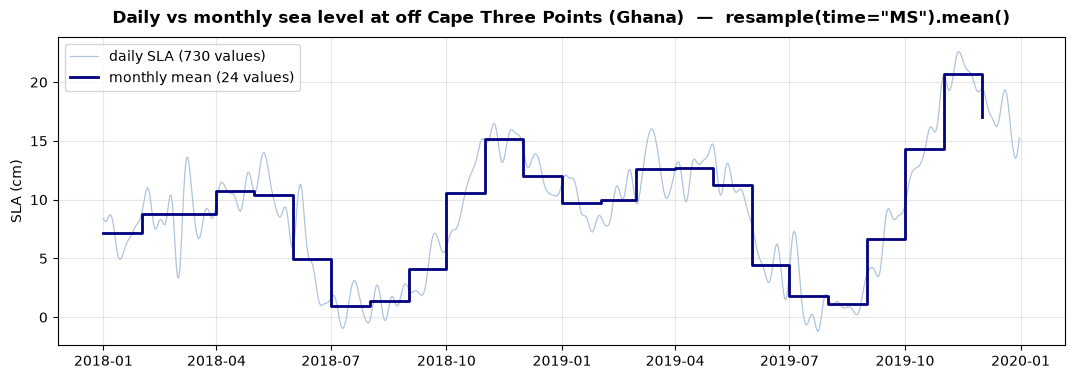

   Days per month used: 28–31   (a gap-free Level 4 product: every day is there)
   The same operation on every grid point gave sla_monthly: 396 months x 160 x 200


In [14]:
# ============================================================
# STEP 2.1 — DAILY -> MONTHLY: WHAT STEP 1.4 DID, AT ONE PLACE
# ─────────────────────────────────────────────────────────────
# Step 1.4 applied resample(time='MS').mean() to every grid point.
# Here we see it at the coastal point, on the daily series in memory.
# ============================================================

daily   = sla_pt
monthly = daily.resample(time='MS').mean()
n_days  = daily.resample(time='MS').count()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.time, daily, color='lightsteelblue', lw=0.9, label=f'daily SLA ({daily.sizes["time"]} values)')
ax.step(monthly.time, monthly, where='post', color='navy', lw=2, label=f'monthly mean ({monthly.sizes["time"]} values)')
ax.set_ylabel('SLA (cm)'); ax.grid(alpha=0.3); ax.legend(loc='upper left')
ax.set_title(f'Daily vs monthly sea level at {cname}  —  resample(time="MS").mean()')
save_fig(fig, f'Day2_resample_daily_monthly_{FILE_PREFIX}.png')
plt.show()
print(f'   Days per month used: {int(n_days.min())}–{int(n_days.max())}   (a gap-free Level 4 product: every day is there)')
print(f'   The same operation on every grid point gave sla_monthly: '
      f'{sla_monthly.sizes["time"]} months x {sla_monthly.sizes["latitude"]} x {sla_monthly.sizes["longitude"]}')

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_SLA_timeseries_trend_GOG.png


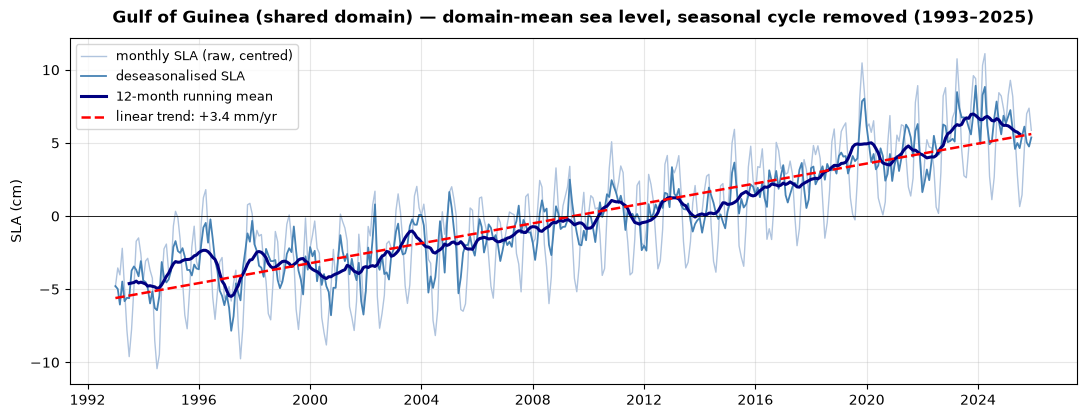

   Trend from deseasonalised data : +3.4 mm/yr  (= +34 cm per century at this rate)
   Trend from raw monthly data    : +3.4 mm/yr  (the seasonal cycle biases it slightly)


In [15]:
# ============================================================
# STEP 2.2 — DOMAIN-MEAN SEA LEVEL AND ITS TREND
# ─────────────────────────────────────────────────────────────
# 1. Domain mean of the monthly maps.
# 2. Remove the mean seasonal cycle (groupby month) -> "deseasonalised"
#    series. NB: SLA is an anomaly relative to 1993–2012, NOT
#    relative to the seasons — the seasonal cycle is still in it.
# 3. Straight-line fit (np.polyfit) on the deseasonalised series.
# ============================================================

sla_mean   = sla_monthly.mean(['latitude', 'longitude'])
seasonal   = sla_mean.groupby('time.month').mean('time')                     # 12 values
sla_deseas = (sla_mean.groupby('time.month') - seasonal).drop_vars('month')  # anomaly vs the seasons

years = (sla_mean.time.dt.year + (sla_mean.time.dt.month - 0.5) / 12).values
slope_raw, _        = np.polyfit(years, sla_mean.values, 1)
slope_cm, intercept = np.polyfit(years, sla_deseas.values, 1)
trend_mm = slope_cm * 10

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(sla_mean.time, sla_mean - float(sla_mean.mean()), color='lightsteelblue', lw=1, label='monthly SLA (raw, centred)')
ax.plot(sla_deseas.time, sla_deseas, color='steelblue', lw=1.3, label='deseasonalised SLA')
ax.plot(sla_deseas.time, sla_deseas.rolling(time=12, center=True).mean(), color='navy', lw=2.2, label='12-month running mean')
ax.plot(sla_deseas.time, slope_cm * years + intercept, 'r--', lw=1.8, label=f'linear trend: {trend_mm:+.1f} mm/yr')
ax.axhline(0, color='k', lw=0.6)
ax.set_ylabel('SLA (cm)'); ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=9)
ax.set_title(f'{DOMAIN_NAME} — domain-mean sea level, seasonal cycle removed ({SSH_PERIOD})')
save_fig(fig, f'Day2_SLA_timeseries_trend_{FILE_PREFIX}.png')
plt.show()
print(f'   Trend from deseasonalised data : {trend_mm:+.1f} mm/yr  (= {trend_mm * 10:+.0f} cm per century at this rate)')
print(f'   Trend from raw monthly data    : {slope_raw * 10:+.1f} mm/yr  (the seasonal cycle biases it slightly)')

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_SLA_seasonal_GOG.png


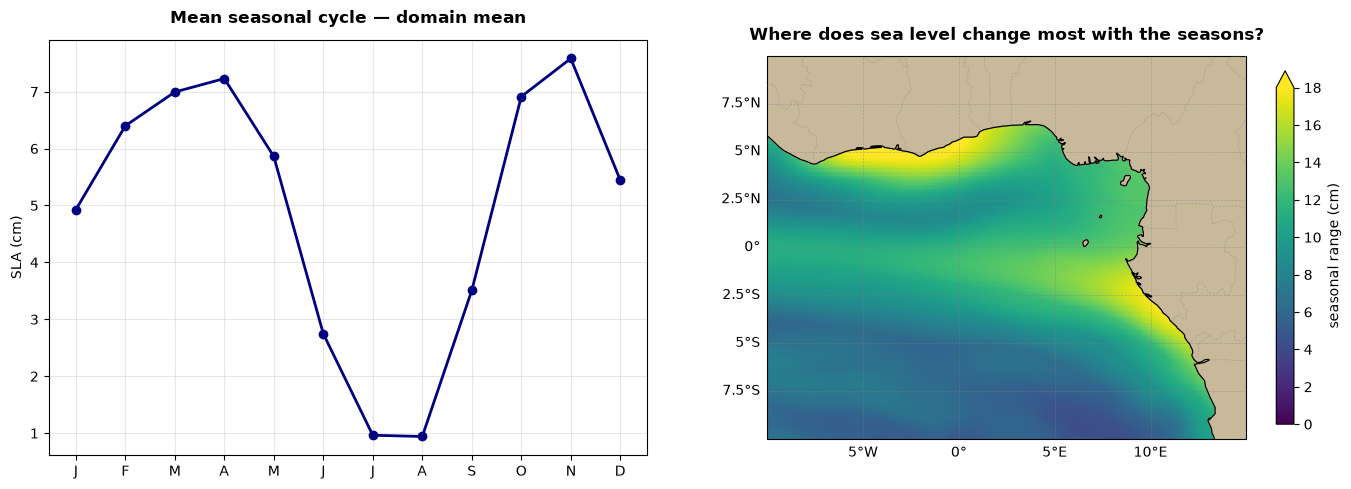

   Highest month: 11   lowest month: 8   range 6.6 cm


In [16]:
# ============================================================
# STEP 2.3 — THE SEASONAL CYCLE OF SEA LEVEL
# ─────────────────────────────────────────────────────────────
# groupby('time.month') -> the mean of each calendar month.
# Left: the domain-mean cycle. Right: WHERE the seasonal
# change is largest (range = highest month − lowest month).
# ============================================================

clim = sla_monthly.groupby('time.month').mean('time')               # 12 maps
clim_mean = clim.mean(['latitude', 'longitude'])                    # domain-mean seasonal cycle
season_range = clim.max('month') - clim.min('month')

fig = plt.figure(figsize=(17, 5.4))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(range(1, 13), clim_mean, 'o-', color='navy', lw=2)
ax1.set_xticks(range(1, 13)); ax1.set_xticklabels(list('JFMAMJJASOND'))
ax1.set_ylabel('SLA (cm)'); ax1.grid(alpha=0.3)
ax1.set_title('Mean seasonal cycle — domain mean')
ax2 = fig.add_subplot(1, 2, 2, projection=PC)
season_range.plot(ax=ax2, transform=PC, cmap='viridis', vmin=0, vmax=float(robust_range(season_range, step=1)[1]),
                  add_labels=False, cbar_kwargs={'label': 'seasonal range (cm)', 'shrink': 0.85})
decorate(ax2, extent=EXTENT)
ax2.set_title('Where does sea level change most with the seasons?')
save_fig(fig, f'Day2_SLA_seasonal_{FILE_PREFIX}.png')
plt.show()
print(f'   Highest month: {int(clim_mean.idxmax())}   lowest month: {int(clim_mean.idxmin())}   '
      f'range {float(clim_mean.max() - clim_mean.min()):.1f} cm')

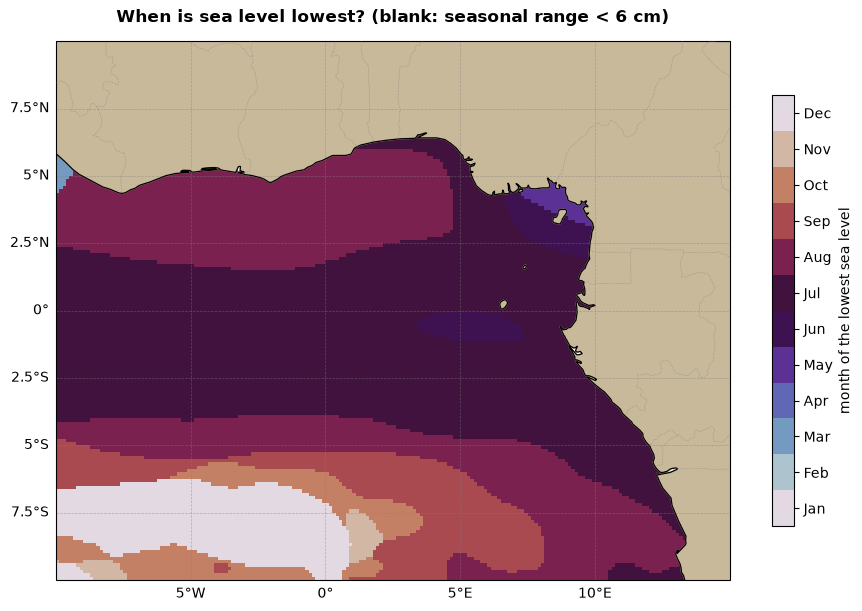

In [17]:
# strong    = season_range >= 6                                   # cm — only where the seasons really matter
month_low = clim.idxmin('month')#.where(strong)
month_low.attrs = {'long_name': 'month of the lowest sea level'}

fig, ax = plt.subplots(figsize=(11, 7), subplot_kw={'projection': PC})
p = month_low.plot(ax=ax, transform=PC, cmap=plt.get_cmap('twilight', 12), vmin=0.5, vmax=12.5, add_labels=False,
                   cbar_kwargs={'ticks': range(1, 13), 'shrink': 0.8, 'label': 'month of the lowest sea level'})
p.colorbar.ax.set_yticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
decorate(ax, extent=EXTENT)
ax.set_title('When is sea level lowest? (blank: seasonal range < 6 cm)')
plt.show()

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_SLA_trend_map_GOG.png


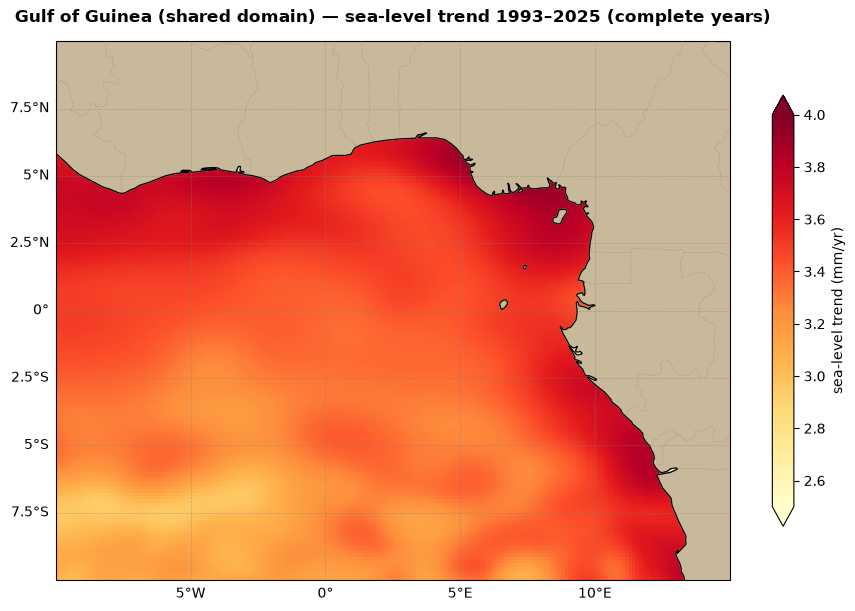

   Years used: 1993–2025 (33 complete years)
   Mean of the trend map: +3.4 mm/yr   (Step 2.2, domain mean: +3.4 mm/yr — should be close)


In [18]:
# ============================================================
# STEP 2.4 — MAP OF THE SEA-LEVEL TREND
# ─────────────────────────────────────────────────────────────
# Same idea as Step 2.2 (a straight-line trend), but at EVERY
# grid point -> WHERE does sea level rise faster or slower?
#   1. keep complete years only (a half year would bias the mean)
#   2. annual means with resample('YS') -> removes the seasons
#   3. use the year number (2010, 2011, …) as the x-axis
#   4. xarray's polyfit fits all grid points at once
# ============================================================

# 1. complete years only (12 months in sla_monthly)
full_years = [y for y, n in sla_monthly.time.dt.year.to_series().value_counts().items() if n == 12]

# 2. one map per year (monthly -> yearly, like daily -> monthly)
sla_annual = sla_monthly.sel(time=sla_monthly.time.dt.year.isin(full_years)).resample(time='YS').mean()

# 3. x-axis = year number, so that the slope is in cm per YEAR
x = sla_annual.assign_coords(year=('time', sla_annual.time.dt.year.values)).swap_dims({'time': 'year'})

# 4. straight line (deg=1) at every grid point; degree=1 is the slope
trend_map = 10 * x.polyfit(dim='year', deg=1)['polyfit_coefficients'].sel(degree=1)   # cm/yr -> mm/yr

fig, ax = plt.subplots(figsize=(11, 7), subplot_kw={'projection': PC})
lo, hi = robust_range(trend_map, step=0.5)
trend_map.plot(ax=ax, transform=PC, cmap='YlOrRd' if lo >= 0 else 'RdBu_r', vmin=lo, vmax=hi, extend='both',
               add_labels=False, cbar_kwargs={'label': 'sea-level trend (mm/yr)', 'shrink': 0.8})
decorate(ax, extent=EXTENT)
ax.set_title(f'{DOMAIN_NAME} — sea-level trend {min(full_years)}–{max(full_years)} (complete years)')
save_fig(fig, f'Day2_SLA_trend_map_{FILE_PREFIX}.png')
plt.show()

print(f'   Years used: {min(full_years)}–{max(full_years)} ({len(full_years)} complete years)')
print(f'   Mean of the trend map: {float(trend_map.mean()):+.1f} mm/yr   '
      f'(Step 2.2, domain mean: {trend_mm:+.1f} mm/yr — should be close)')

### 🔎 Reading Section 2

- **The trend.** The regional sea level rises by a few **millimetres per year** — comparable to the global mean
  (≈ 3–4 mm/yr over recent decades). For a low-lying coast such as Cotonou or Lagos, that is tens of centimetres per century,
  added to tides, storms and land subsidence.
- **The seasonal cycle.** Sea level has a clear annual cycle of a few centimetres. Look at **where** the seasonal range is
  largest on the map: along the coast and the equatorial band — the regions where the thermocline moves up and down with the seasons.
- **The map of trends** is not uniform: ocean circulation redistributes the rise.

<div style="border-left:6px solid #6B7280; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#6B7280">⚠️ Careful with trends</b><br>16 years (6 in LIGHT_MODE) is short: interannual events (e.g. Atlantic Niño years) can bias a straight-line fit. The all-satellite product used here is designed for mapping; climate studies of sea-level rise use a specially stabilised record.</div>

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (5 min)</b><br>1. In which month is the domain-mean sea level <b>lowest</b>? Does it match the cold season seen on Day 1?<br>2. On the seasonal-range map, find the two regions where sea level changes most. What do they have in common with the cold waters of Day 1?<br>3. <b>Challenge:</b> compute the trend of the <b>first</b> and the <b>second</b> half of the period separately (hint: <code>sla_mean.sel(time=slice(...))</code>). Is the rise accelerating?</div>

## Section 3 — From Sea Level to Currents

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Dynamics block · 13:30–14:30</span> &nbsp; **MOOC Module 2 — Fundamentals of ocean dynamics**

### Geostrophic balance

Away from the equator, large-scale currents are in **geostrophic balance**: the push of the sea-surface slope
(pressure gradient) is balanced by the Coriolis force. The current flows **along** the contours of ADT, not down the slope:

$$ u_g = -\frac{g}{f}\,\frac{\partial \eta}{\partial y}, \qquad v_g = \frac{g}{f}\,\frac{\partial \eta}{\partial x}, \qquad f = 2\Omega\sin\varphi $$

with η = ADT. In the Northern Hemisphere the high sea level is on the **right** of the flow; in the Southern Hemisphere, on the left.

- A slope of only **10 cm over 100 km** at 5°N drives a current of about **1 m/s**.
- At the **equator** f → 0: the formula divides by zero and **breaks down**. We mask ±2° around it.

We will compute the currents **by hand** from ADT and compare with the product's own `ugos`, `vgos`.

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_ADT_geostrophic_GOG.png


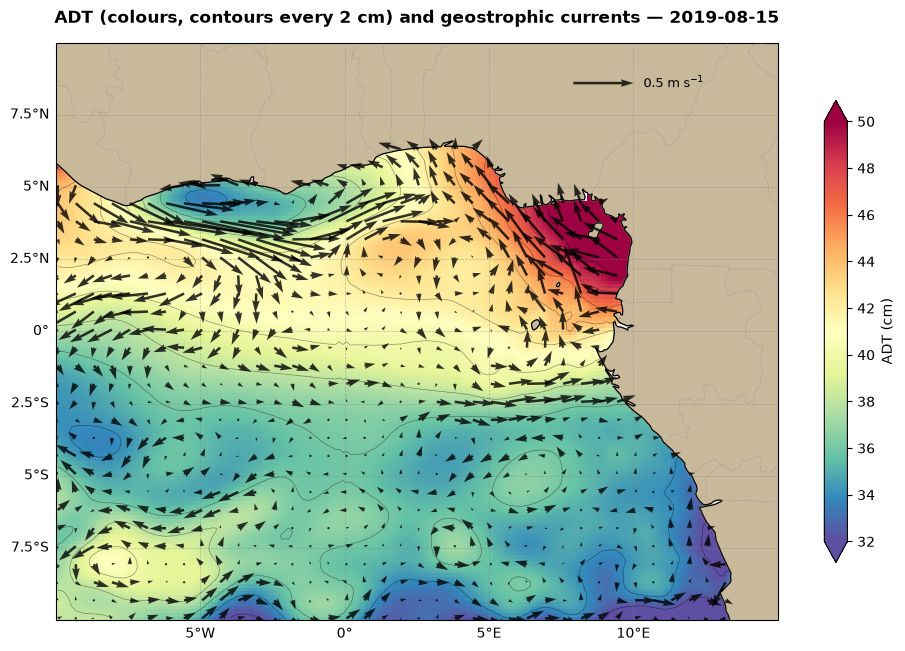

In [19]:
# ============================================================
# STEP 3.1 — THE CIRCULATION OF THE DAY: ADT + GEOSTROPHIC CURRENTS
# ============================================================

circ = ds_ssh[['adt', 'ugos', 'vgos']].sel(time=SNAP_DATE, method='nearest').compute()

fig, ax = plt.subplots(figsize=(12, 7.5), subplot_kw={'projection': PC})
adt_cm = 100 * circ['adt']
lo, hi = robust_range(adt_cm, step=1)
adt_cm.plot(ax=ax, transform=PC, cmap='Spectral_r', vmin=lo, vmax=hi, add_labels=False,
            cbar_kwargs={'label': 'ADT (cm)', 'shrink': 0.8})
ax.contour(adt_cm.longitude, adt_cm.latitude, adt_cm, levels=np.arange(lo, hi + 1, 2),
           colors='k', linewidths=0.4, alpha=0.5, transform=PC, zorder=3)
arrows(ax, circ['ugos'], circ['vgos'], n_across=35, scale=6, key=0.5, key_label='0.5 m s$^{-1}$',
       key_xy=(0.80, 0.93))
decorate(ax, extent=EXTENT)
ax.set_title(f'ADT (colours, contours every 2 cm) and geostrophic currents — {str(circ.time.values)[:10]}')
save_fig(fig, f'Day2_ADT_geostrophic_{FILE_PREFIX}.png')
plt.show()

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_geostrophy_by_hand_GOG.png


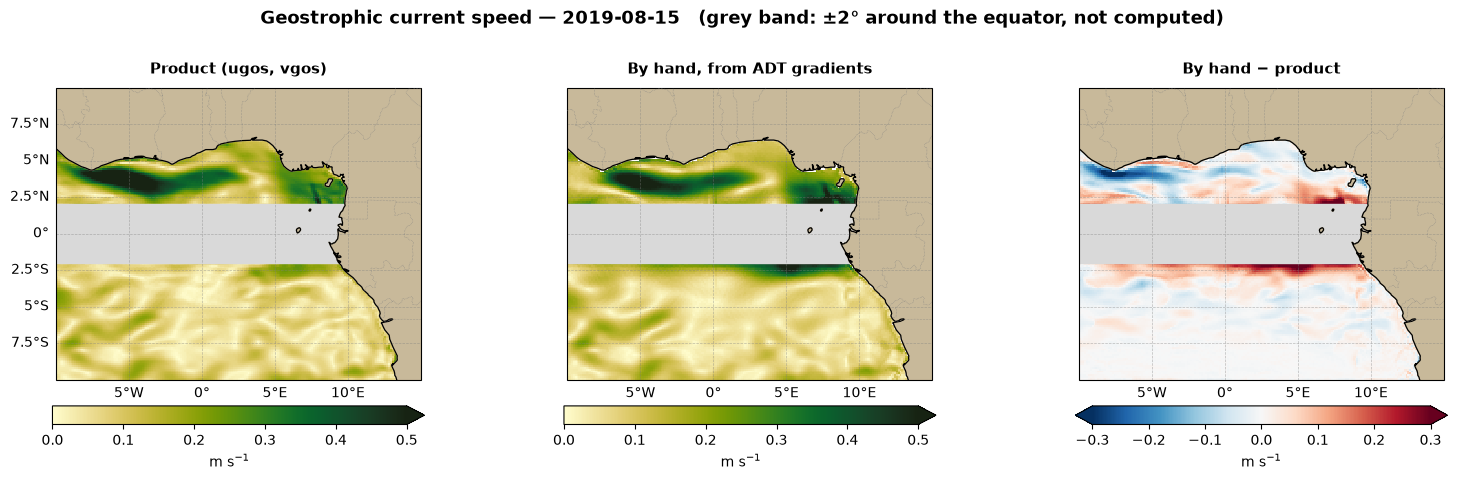

   RMS difference by hand vs product: 0.066 m/s


In [20]:
# ============================================================
# STEP 3.2 — GEOSTROPHIC CURRENTS BY HAND, FROM ADT GRADIENTS
# ─────────────────────────────────────────────────────────────
# Gradients in metres: 1° latitude = 111 km; 1° longitude =
# 111 km × cos(latitude). Masked within ±EQUATOR_MASK_DEG.
# ============================================================

g, OMEGA, R = 9.81, 7.2921e-5, 6.371e6
eta = circ['adt']                                               # metres
deg = np.pi / 180
f = 2 * OMEGA * np.sin(np.deg2rad(eta.latitude))
deta_dy = eta.differentiate('latitude') / (R * deg)
deta_dx = eta.differentiate('longitude') / (R * deg * np.cos(np.deg2rad(eta.latitude)))

far_from_equator = np.abs(eta.latitude) >= EQUATOR_MASK_DEG
u_hand = (-g / f * deta_dy).where(far_from_equator)
v_hand = ( g / f * deta_dx).where(far_from_equator)

speed_hand = np.hypot(u_hand, v_hand)
speed_prod = np.hypot(circ['ugos'], circ['vgos']).where(far_from_equator)
diff = speed_hand - speed_prod
rmse = float(np.sqrt((diff ** 2).mean()))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.04, right=0.97, top=0.82, bottom=0.10, wspace=0.10)
vmax = float(robust_range(speed_prod, step=0.1)[1])
for ax, field, title, cmap, lims in [(axes[0], speed_prod, 'Product (ugos, vgos)', cmocean.cm.speed, (0, vmax)),
                                     (axes[1], speed_hand, 'By hand, from ADT gradients', cmocean.cm.speed, (0, vmax)),
                                     (axes[2], diff, 'By hand − product', 'RdBu_r', (-0.3, 0.3))]:
    field.plot(ax=ax, transform=PC, cmap=cmap, vmin=lims[0], vmax=lims[1], add_labels=False,
               cbar_kwargs={'label': 'm s$^{-1}$', 'orientation': 'horizontal', 'shrink': 0.8, 'pad': 0.07})
    ax.axhspan(-EQUATOR_MASK_DEG, EQUATOR_MASK_DEG, color='0.85', zorder=1, transform=PC)
    decorate(ax, extent=EXTENT, left=(ax is axes[0]))
    ax.set_title(title, fontsize=11)
fig.suptitle(f'Geostrophic current speed — {str(circ.time.values)[:10]}   (grey band: ±{EQUATOR_MASK_DEG:g}° around the equator, not computed)',
             fontsize=13, fontweight='bold', y=0.97)
save_fig(fig, f'Day2_geostrophy_by_hand_{FILE_PREFIX}.png')
plt.show()
print(f'   RMS difference by hand vs product: {rmse:.3f} m/s')

### 🔎 Reading the geostrophic currents

- **The arrows follow the ADT contours**, and they are fastest where the contours are **closest together** (steep slope).
- **By hand vs product:** the patterns agree well away from the equator. The differences grow towards the grey band,
  where f is small and tiny errors in the slope give large errors in speed. The product uses a special treatment near the equator.
- In the Gulf of Guinea, look for the **Guinea Current**: an **eastward** flow along the northern coast (around 3–5°N).

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (3 min)</b><br>Set <code>EQUATOR_MASK_DEG = 0.5</code> in Step 0.5 and re-run Steps 0.5, 3.1 and 3.2. What happens to the hand-computed speeds near the equator, and why?</div>

### 3.3 — Eddies: where is the ocean most turbulent?

The **anomalies** of the geostrophic current (`ugosa`, `vgosa`) describe eddies and other departures from the mean flow.
Their energy per unit mass is the **Eddy Kinetic Energy**:

$$ \mathrm{EKE} = \tfrac{1}{2}\,\overline{u'^2 + v'^2} $$

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_EKE_GOG.png


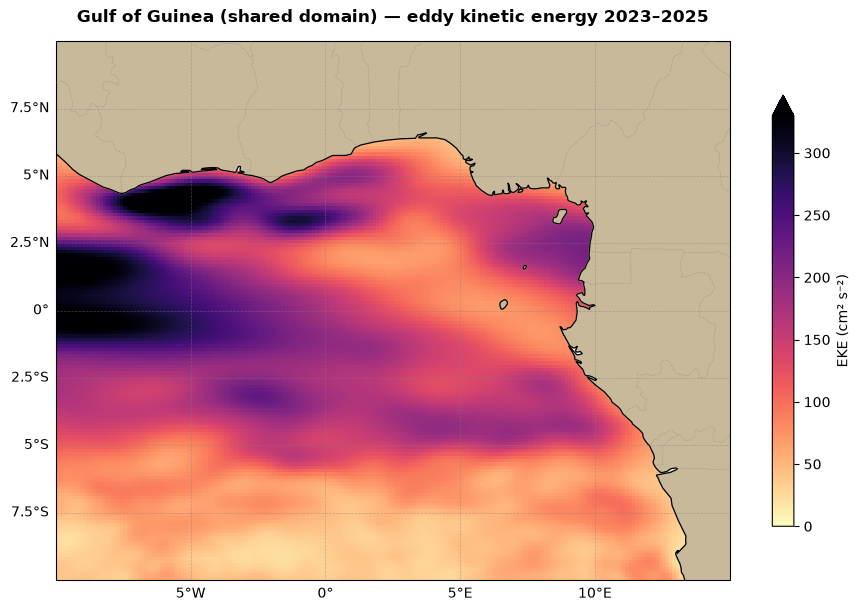

   Domain-mean EKE: 133 cm²/s²   maximum: 420 cm²/s²


In [21]:
# ============================================================
# STEP 3.3 — EDDY KINETIC ENERGY (computed in Step 1.4)
# ─────────────────────────────────────────────────────────────
# eke = mean over EKE_START -> DATE_END of ½(u'² + v'²), from the
# daily anomalies of the geostrophic current (ugosa, vgosa).
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7), subplot_kw={'projection': PC})
eke.plot(ax=ax, transform=PC, cmap='magma_r', vmin=0, vmax=float(robust_range(eke, step=10)[1]), add_labels=False,
         cbar_kwargs={'label': 'EKE (cm² s⁻²)', 'shrink': 0.8})
decorate(ax, extent=EXTENT)
ax.set_title(f'{DOMAIN_NAME} — eddy kinetic energy {EKE_START[:4]}–{DATE_END[:4]}')
save_fig(fig, f'Day2_EKE_{FILE_PREFIX}.png')
plt.show()
print(f'   Domain-mean EKE: {float(eke.mean()):.0f} cm²/s²   maximum: {float(eke.max()):.0f} cm²/s²')

### 🔎 Reading the EKE map

High EKE marks **energetic, eddying** regions; low EKE, a calm ocean. In the Gulf of Guinea, the highest values usually sit
**near the equator** (strong, variable equatorial currents and waves) — partly an artefact of the geostrophic calculation there.
In the **Agulhas** (Area 3, this afternoon) EKE is several times larger: one of the most energetic regions of the world ocean.

> Keep the domain-mean EKE value printed above: in the Gallery Walk, the three subgroups will compare their numbers.

## Section 4 — The Model's Sea Level

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Model block · 14:30–15:00</span> &nbsp; **MOOC Module 3 — Numerical ocean models · Module 4 — Data assimilation**

### What is an ocean reanalysis?

**GLORYS12** is the Copernicus Marine global ocean **reanalysis**:

| | |
|---|---|
| **Model** | NEMO — solves the equations of motion, heat and salt on a grid |
| **Grid** | 1/12° (≈ 9 km) horizontally, **50 levels** from the surface to the bottom |
| **Forcing** | the atmosphere from the ERA reanalyses (wind, heat, fresh water — Module 5) |
| **Assimilation** | every week the model is **corrected** towards the observations: along-track **altimetry** (what you saw in 1.3), satellite SST, **Argo** temperature and salinity profiles, sea ice |
| **Result** | a complete, physically consistent 3-D ocean, every day since 1993 |

The model's sea surface height is called **`zos`**. Because altimetry is assimilated, `zos` should be **close** to the observed ADT — but not identical:
the model has its own mean surface, a finer grid, and physics that fills the gaps between observations.

> **Module 3 idea to keep:** observations are accurate but sparse; models are complete but imperfect. **Assimilation** combines the two.

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_model_vs_altimetry_map_GOG.png


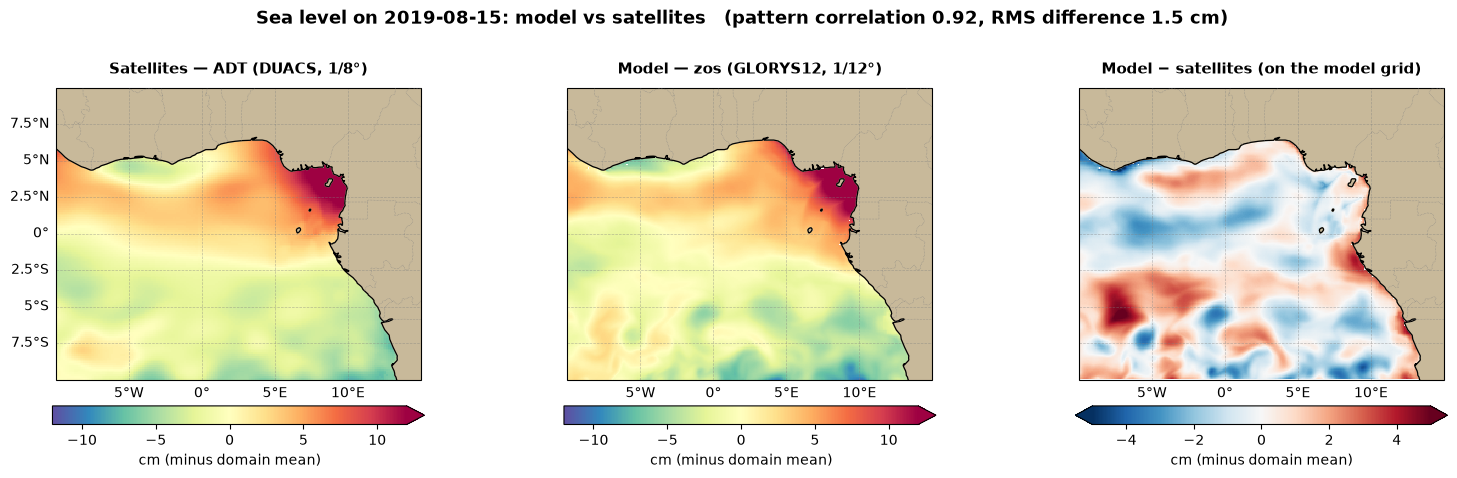

In [22]:
# ============================================================
# STEP 4.1 — MODEL vs SATELLITE SEA LEVEL ON THE SAME DAY
# ─────────────────────────────────────────────────────────────
# The model and the altimetry have different reference levels,
# so we compare the PATTERNS: each field minus its own domain mean.
# The satellite map (1/8°) is interpolated onto the model grid (1/12°).
# (Both fields of SNAP_DATE were loaded in Step 1.4.)
# ============================================================

zos_pat = zos_day - zos_day.mean()
adt_pat = adt_obs - adt_obs.mean()
adt_on_mod = adt_pat.interp_like(zos_pat)                       # satellites (1/8°) on the model grid (1/12°)
diff = zos_pat - adt_on_mod
r = float(xr.corr(zos_pat, adt_on_mod))
rms = float(np.sqrt((diff ** 2).mean()))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.04, right=0.97, top=0.82, bottom=0.10, wspace=0.10)
lim = max(abs(np.array(robust_range(adt_pat, step=1))))
for ax, field, title, cmap, l in [(axes[0], adt_pat, 'Satellites — ADT (DUACS, 1/8°)', 'Spectral_r', lim),
                                  (axes[1], zos_pat, 'Model — zos (GLORYS12, 1/12°)', 'Spectral_r', lim),
                                  (axes[2], diff, 'Model − satellites (on the model grid)', 'RdBu_r', 5)]:
    field.plot(ax=ax, transform=PC, cmap=cmap, vmin=-l, vmax=l, add_labels=False,
               cbar_kwargs={'label': 'cm (minus domain mean)', 'orientation': 'horizontal', 'shrink': 0.8, 'pad': 0.07})
    decorate(ax, extent=EXTENT, left=(ax is axes[0]))
    ax.set_title(title, fontsize=11)
fig.suptitle(f'Sea level on {SNAP_DATE}: model vs satellites   (pattern correlation {r:.2f}, RMS difference {rms:.1f} cm)',
             fontsize=13, fontweight='bold', y=0.97)
save_fig(fig, f'Day2_model_vs_altimetry_map_{FILE_PREFIX}.png')
plt.show()

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_model_vs_altimetry_points_GOG.png


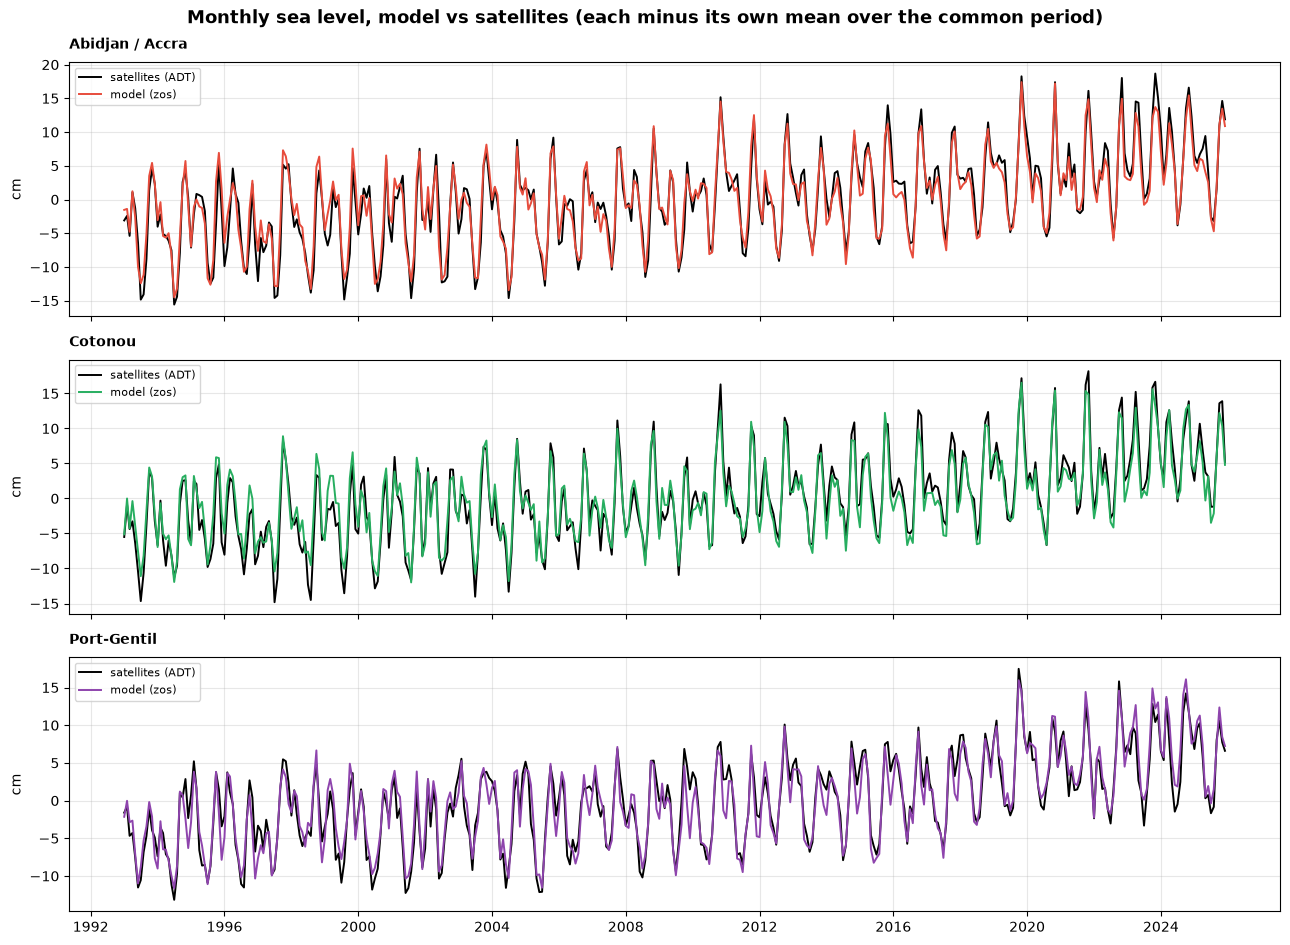

,correlation,RMS difference (cm),model point,satellites,common period
point,,,,,
Abidjan / Accra,0.97,1.8,"-3.50°, 5.00°",interpolated to the model point,1993-01 → 2025-12
Cotonou,0.96,1.8,"2.50°, 6.00°",interpolated to the model point,1993-01 → 2025-12
Port-Gentil,0.95,1.8,"9.50°, 1.00°",interpolated to the model point,1993-01 → 2025-12


In [23]:
# ============================================================
# STEP 4.2 — MODEL vs SATELLITE AT THE REFERENCE POINTS
# ─────────────────────────────────────────────────────────────
# Monthly series loaded in Step 1.4: the nearest MODEL ocean point
# of each place, and the satellites interpolated to that point.
# Both are cut to their COMMON period before removing their means.
# ============================================================

rows, series = [], []
for label, p in point_series.items():
    obs, mod = xr.align(p['obs'].dropna('time'), p['mod'].dropna('time'), join='inner')   # common period only
    obs, mod = obs - obs.mean(), mod - mod.mean()
    series.append((label, obs, mod))
    rows.append({'point': label,
                 'correlation': round(float(xr.corr(obs, mod)), 2),
                 'RMS difference (cm)': round(float(np.sqrt(((mod - obs) ** 2).mean())), 1),
                 'model point': f'{p["lon"]:.2f}°, {p["lat"]:.2f}°',
                 'satellites': p['how'],
                 'common period': f'{str(obs.time.values[0])[:7]} → {str(obs.time.values[-1])[:7]}'})

fig, axes = plt.subplots(len(series), 1, figsize=(13, 3.2 * len(series)), sharex=True)
for ax, (label, obs, mod), color in zip(np.atleast_1d(axes), series, COLORS):
    ax.plot(obs.time, obs, color='k', lw=1.4, label='satellites (ADT)')
    ax.plot(mod.time, mod, color=color, lw=1.4, label='model (zos)')
    ax.set_ylabel('cm'); ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8)
    ax.set_title(label, loc='left', fontsize=10)
fig.suptitle('Monthly sea level, model vs satellites (each minus its own mean over the common period)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig(fig, f'Day2_model_vs_altimetry_points_{FILE_PREFIX}.png')
plt.show()
display(pd.DataFrame(rows).set_index('point'))

### 🔎 Reading the model–satellite comparison

- **High correlation** (usually above 0.8 for monthly values): the model follows the observed seasonal cycle and the
  year-to-year changes — expected, since it **assimilates** altimetry.
- **Differences of a few centimetres** remain, especially near the **coast**, where altimetry is less reliable and the
  model resolves narrower coastal currents.
- The model map shows **finer detail** (1/12° vs 1/8°, and no interpolation between satellite tracks).

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">Why not just use the model?</b><br>Because the model is only as good as the observations that constrain it. Where observations are sparse (subsurface, coasts, under clouds for SST), the model relies on its physics — which is exactly where it is most uncertain. Using both, and knowing where each is weak, is the professional approach (Modules 3, 4 and 6).</div>

## Section 5 — Below the Surface

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Subsurface block · 15:20–16:20</span> &nbsp; **MOOC Modules 3 and 2** — and the answer to the Day 1 puzzle

Satellites see the surface; the **model** gives us the ocean **with depth**. Two views:

1. **A section** — a vertical slice of temperature along a line, in **March** and in **August**.
2. **A depth–time diagram** at a coastal point — temperature every day, from the surface to 200 m, over two years,
   next to the satellite sea level at the same place.

We follow the **thermocline** with the **20 °C isotherm** (the depth where the water is 20 °C, called **D20**), a standard marker in the tropical Atlantic.
In the cooler Mauritanian upwelling and the deep Agulhas Current the 20 °C line is not always present, so Areas 1 and 3 use the **15 °C isotherm** (set automatically in Step 0.5).

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">💡 Daily or monthly?</b><br>The section uses the <b>monthly</b> model dataset: a 3-D climatology over many years needs only monthly means, and 3-D daily fields would be far too much to stream for a whole room. The depth–time diagram at one point uses the <b>daily</b> data, resampled where needed — the technique of Day 1.</div>

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_section_March_August_GOG.png


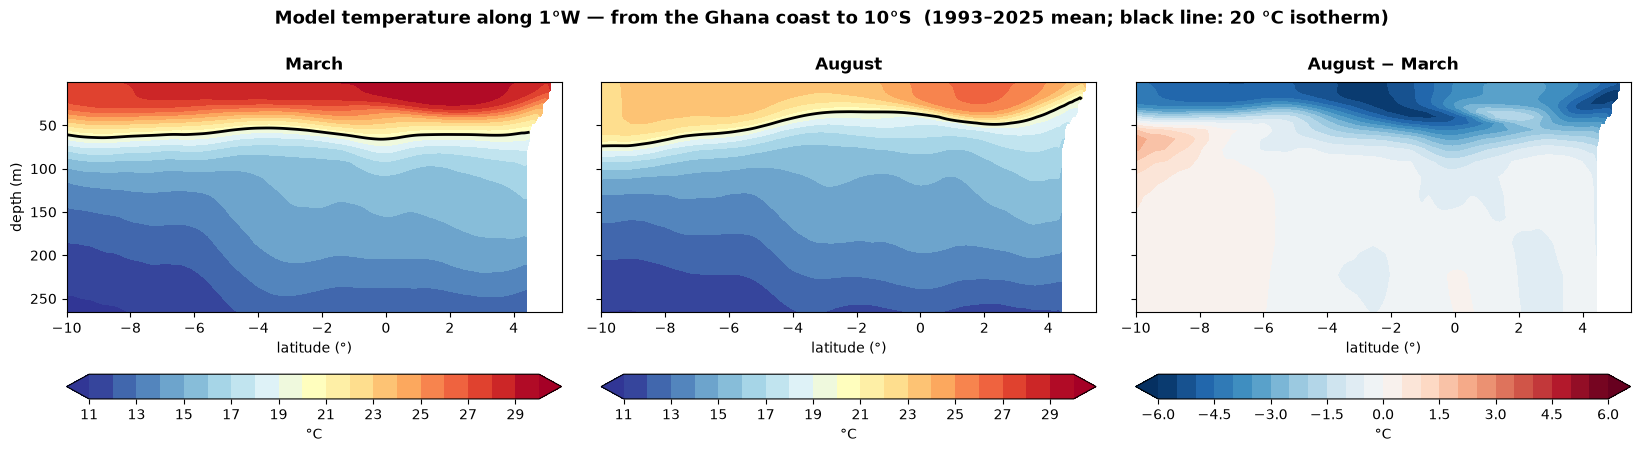

In [24]:
# ============================================================
# STEP 5.1 — A VERTICAL SECTION: MARCH vs AUGUST (model, monthly)
# ─────────────────────────────────────────────────────────────
# sec_clim (loaded in Step 1.4) = the mean of all Marches and all
# Augusts of the period, averaged across the thin section box.
# ============================================================

tlo, thi = robust_range(sec_clim, step=1)
tlevels = np.arange(tlo, thi + 0.5, 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
fig.subplots_adjust(left=0.05, right=0.97, top=0.84, bottom=0.18, wspace=0.08)
for ax, (field, title, cmap, levels) in zip(axes, [
        (sec_clim.sel(month=3), 'March', 'RdYlBu_r', tlevels),
        (sec_clim.sel(month=8), 'August', 'RdYlBu_r', tlevels),
        (sec_clim.sel(month=8) - sec_clim.sel(month=3), 'August − March', 'RdBu_r', np.arange(-6, 6.5, 0.5))]):
    cf = ax.contourf(field[along], field.depth, field, levels=levels, cmap=cmap, extend='both')
    if title != 'August − March':
        ax.contour(field[along], field.depth, field, levels=[ISOTHERM], colors='k', linewidths=2)
    ax.set_title(title); ax.set_xlabel(f'{along} (°)')
    fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.18, label='°C')
axes[0].invert_yaxis(); axes[0].set_ylabel('depth (m)')
fig.suptitle(f'Model temperature along {SECTION["label"]}  ({PERIOD} mean; black line: {ISOTHERM:.0f} °C isotherm)',
             fontsize=13, fontweight='bold', y=0.98)
save_fig(fig, f'Day2_section_March_August_{FILE_PREFIX}.png')
plt.show()

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_thermocline_vs_SLA_GOG.png


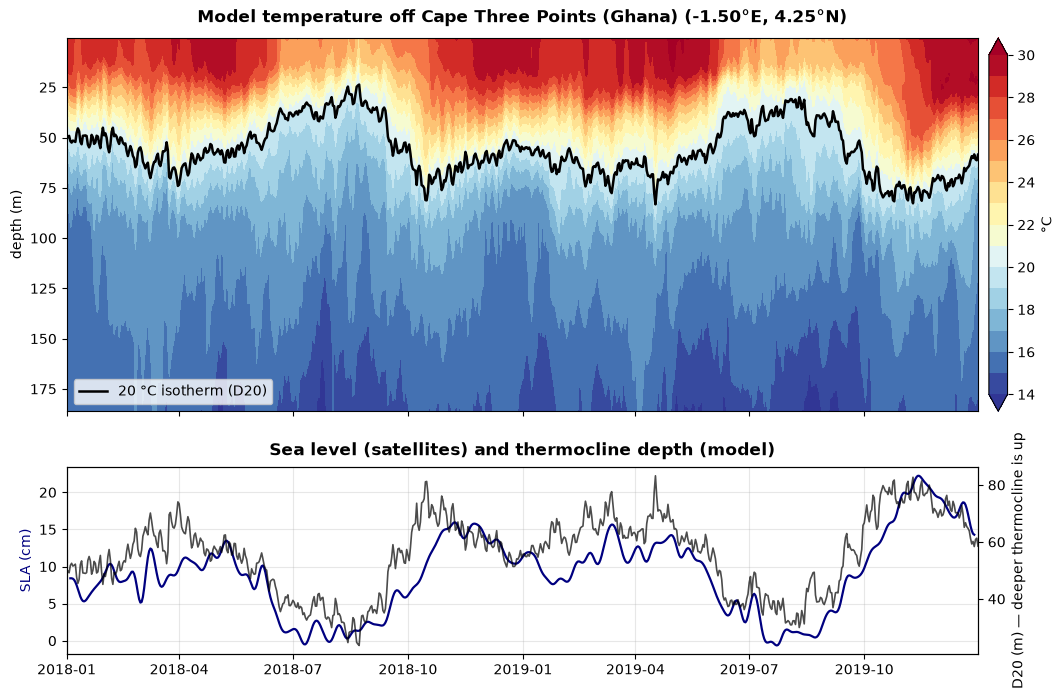

   Correlation between D20 and SLA: r = 0.88
   D20 range: 24 m (shallowest) to 83 m (deepest)


In [26]:
# ============================================================
# STEP 5.2 — DEPTH–TIME AT THE COASTAL POINT, WITH SEA LEVEL
# ─────────────────────────────────────────────────────────────
# Model temperature, daily, two years (loaded in Step 1.4); the depth of the
# ISOTHERM (20 °C in the shared domain: 'D20'); and the satellite
# SLA at the same point.
# ============================================================

# prof (daily model profiles) and sla_pt (daily satellite SLA) were loaded in Step 1.4


def isotherm_depth(profiles, temp=20.0):
    """Depth (m) where each daily profile crosses `temp`, by linear interpolation."""
    z = profiles.depth.values
    out = np.full(profiles.sizes['time'], np.nan)
    for i, t in enumerate(profiles.values):
        below = np.where(t < temp)[0]
        if len(below) and below[0] > 0:
            k = below[0]
            out[i] = z[k - 1] + (temp - t[k - 1]) * (z[k] - z[k - 1]) / (t[k] - t[k - 1])
    return xr.DataArray(out, coords={'time': profiles.time}, dims='time', name=f'D{temp:.0f}')

d20 = isotherm_depth(prof, ISOTHERM)
DLAB = f'D{ISOTHERM:.0f}'                      # 'D20' in the shared domain

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
plo, phi = robust_range(prof, step=1)
cf = axes[0].contourf(prof.time, prof.depth, prof.T, levels=np.arange(plo, phi + 0.5, 1), cmap='RdYlBu_r', extend='both')
axes[0].plot(d20.time, d20, color='k', lw=1.8, label=f'{ISOTHERM:.0f} °C isotherm ({DLAB})')
axes[0].invert_yaxis(); axes[0].set_ylabel('depth (m)'); axes[0].legend(loc='lower left')
fig.colorbar(cf, ax=axes[0], pad=0.01, label='°C')
axes[0].set_title(f'Model temperature {cname} ({plon:.2f}°E, {plat:.2f}°N)')
axes[1].plot(sla_pt.time, sla_pt.rolling(time=7, center=True).mean(), color='navy', lw=1.6, label='satellite SLA (7-day mean)')
axes[1].set_ylabel('SLA (cm)', color='navy'); axes[1].grid(alpha=0.3)
ax2 = axes[1].twinx()
ax2.plot(d20.time, d20, color='k', lw=1.2, alpha=0.7, label=DLAB)
ax2.set_ylabel(f'{DLAB} (m) — deeper thermocline is up')
axes[1].set_title('Sea level (satellites) and thermocline depth (model)')
fig.colorbar(cf, ax=axes[1], pad=0.01).ax.set_visible(False)          # keep the two panels aligned
save_fig(fig, f'Day2_thermocline_vs_SLA_{FILE_PREFIX}.png')
plt.show()

both = xr.merge([d20, sla_pt.rename('sla').drop_vars(['longitude', 'latitude'], errors='ignore')], join='inner').dropna('time')
both_shared = both
print(f'   Correlation between {DLAB} and SLA: r = {float(xr.corr(both[d20.name], both["sla"])):.2f}')
print(f'   {DLAB} range: {float(d20.min()):.0f} m (shallowest) to {float(d20.max()):.0f} m (deepest)')

### 🔎 Answering the Day 1 puzzle

- **The section (Step 5.1).** In **August** the 20 °C line rises towards the surface at the **equator** (to ~35 m) and especially
  at the **Ghana coast** (to ~20 m), while it deepens further south. The cooling (up to −6 °C) is confined to the upper ~80 m:
  cold water is **lifted from the thermocline**, not cooled from above.
- **The depth–time diagram (Step 5.2).** Each year, from **July to September**, the 20 °C isotherm at the coastal point rises from
  ~55 m to **~25–35 m**; in **October–November** it sinks to ~80 m. The satellite sea level follows it closely: **~0–2 cm** when the
  thermocline is shallow, **~15–20 cm** when it is deep — the two curves **move together** (positive correlation: deep thermocline ↔ high sea level).
  *Note: in the lower panel the D20 axis is flipped (deeper is up), so that it can be compared directly with sea level; in the upper panel depth increases downwards, as usual.*

**So where does the cold coastal water come from?** Not mainly from the local wind (Day 1: the local Ekman transport is onshore).
The **thermocline itself is lifted** in boreal summer, at the equator and along the coast. Ocean scientists attribute this to a combination of:

1. **Remote forcing:** the trade winds strengthen in the western equatorial Atlantic; the signal travels east along the equator
   as **equatorial Kelvin waves**, then along the African coast as **coastal-trapped waves**, lifting the thermocline as it goes;
2. the **Guinea Current** and the **capes** (Cape Palmas, Cape Three Points), which favour upwelling downstream of them;
3. the **local wind**, which contributes, but is not the main driver.

**The satellites saw the sea level drop; the model showed why.** That is the value of combining observations and models (Modules 3 and 4).

## Section 6 — First Look at Your Region

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Subgroup block · 16:20–17:20</span>

Until now everyone worked the **shared Gulf of Guinea domain**. Tomorrow (Day 3) each subgroup works **all day on its own region**:
forecast, validate, and write a bulletin for real users. This last hour is a **first look**: what does your region look like
through today's tools, and what do you want to find out tomorrow?

**How:** in the cell below, set **`MY_AREA`** to your subgroup's number and run it. Nothing else to change — no need to go back
to Step 0.5. The cell loads your region's data **once** (like Step 1.4, but a smaller box: a few minutes) and draws a one-page
dashboard. This morning's results stay in memory.

| Area | Region | Look first at |
|---|---|---|
| **1** | Mauritania / Senegal — Canary upwelling | When is sea level lowest? Is the thermocline lifted at the same time? |
| **2** | Gulf of Guinea, eastern part — equator and rivers | Does the boreal-summer rise of the thermocline seen this morning also reach this area? |
| **3** | Agulhas — western boundary current | How much more energetic than the Gulf of Guinea? (EKE) — remember: **Southern Hemisphere** |

==> Area 1 — Mauritania / Senegal  (Canary Eastern Boundary Upwelling System)
   Coastal point used: -17.67°E, 20.00°N (sea at least 200 m deep)


WARNING - 2026-10-28T16:19:52Z - Some of your subset selection [0.0, 300.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
WARNING - 2026-10-28T16:19:57Z - Some of your subset selection [0.0, 200.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


   Loading Area 1 (one progress bar):
[########################################] | 100% Completed | 42.82 s
   Loaded in 0.7 min
==> Saved: ~/OPERA_Workshop/Day2/output/Day2_first_look_MRS.png


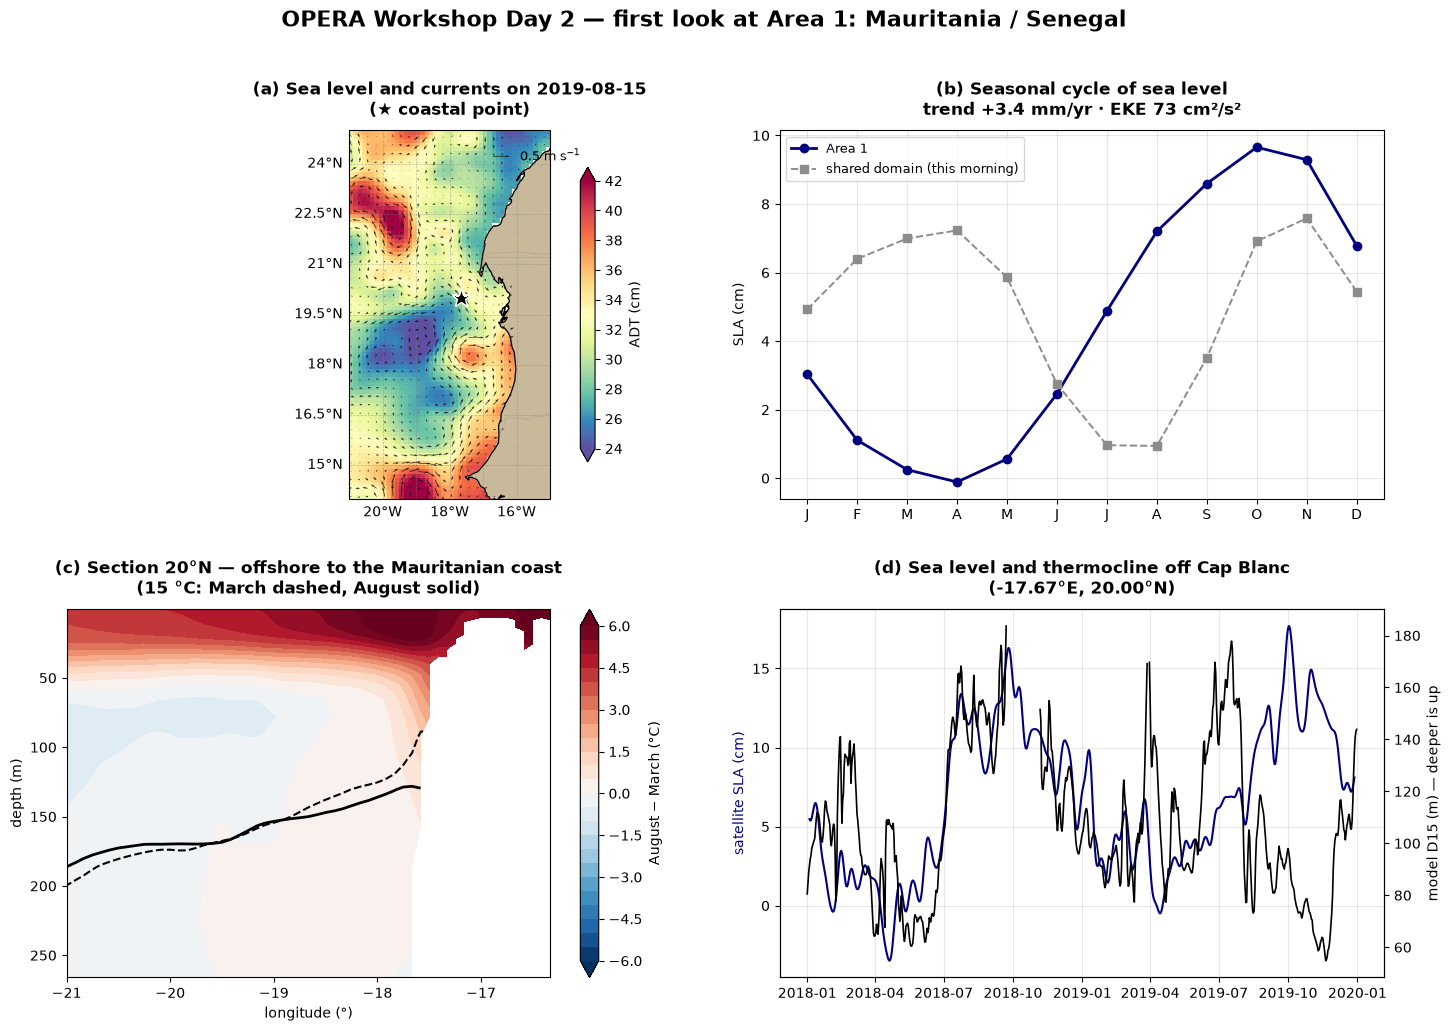

,Area 1,Shared domain (this morning)
Sea-level trend (mm/yr),+3.4,+3.4
Seasonal range of sea level (cm),9.8,6.6
Mean eddy energy (cm²/s²),73,133
Thermocline depth at the coastal point,55–184 m (D15),24–83 m (D20)
Correlation thermocline – sea level,0.20,0.88


In [29]:
# ============================================================
# STEP 6.1 — FIRST LOOK AT YOUR REGION  (Subgroups)
# ─────────────────────────────────────────────────────────────
# Set MY_AREA, then run. The cell:
#   1. loads your region's data ONCE (one progress bar),
#   2. draws a one-page dashboard, saved for the Gallery Walk,
#   3. compares your region with this morning's shared domain.
#
#   '1' Mauritania / Senegal   '2' Gulf of Guinea — east   '3' Agulhas
# ============================================================

MY_AREA = '1'          # <- your subgroup's area: '1', '2' or '3'

A = ZONES[MY_AREA]
A_BOX = dict(minimum_longitude=A['lon'][0], maximum_longitude=A['lon'][1],
             minimum_latitude=A['lat'][0],  maximum_latitude=A['lat'][1])
A_EXTENT = [*A['lon'], *A['lat']]
A_ISO = A['isotherm']; A_DLAB = f'D{A_ISO:.0f}'
A_KEY_XY = {'1': (0.80, 0.93), '2': (0.80, 0.93), '3': (0.45, 0.93)}[MY_AREA]   # NEW: arrow key over land
print(f"==> Area {MY_AREA} — {A['name']}  ({A['regime']})")
if A['hemisphere'] == 'S':
    print('   !! Southern Hemisphere — JJA is WINTER, DJF is SUMMER.')

# ---- one day (small): the circulation of the day ----
a_circ = stream('SSH', start=SNAP_DATE, end=SNAP_DATE, box=A_BOX, service='arco-geo-series')[['adt', 'ugos', 'vgos']].isel(time=0).compute()

# ---- the coastal point: nearest model point DEEP enough for the whole profile ----     # CHANGED
a_clon, a_clat, a_cname = A['coast_point']
a_plon, a_plat = nearest_deep_point(a_clon, a_clat, A['profile_depth'], SNAP_DATE)
print(f"   Coastal point used: {a_plon:.2f}°E, {a_plat:.2f}°N (sea at least {A['profile_depth']} m deep)")

sd = A['section']
if sd['kind'] == 'meridional':
    a_sbox = dict(minimum_longitude=sd['lon'] - 0.05, maximum_longitude=sd['lon'] + 0.05,
                  minimum_latitude=sd['lat'][0], maximum_latitude=sd['lat'][1])
    a_along, a_across = 'latitude', 'longitude'
else:
    a_sbox = dict(minimum_longitude=sd['lon'][0], maximum_longitude=sd['lon'][1],
                  minimum_latitude=sd['lat'] - 0.05, maximum_latitude=sd['lat'] + 0.05)
    a_along, a_across = 'longitude', 'latitude'

# ---- the recipe (lazy), then ONE compute — as in Step 1.4 ----
a_ts  = stream('SSH', box=A_BOX, service='arco-time-series')
a_sec = stream('MODEL_M', box=a_sbox, minimum_depth=0, maximum_depth=A['section_depth'], service='arco-time-series')['thetao']
a_sec = a_sec.sel(time=a_sec.time.dt.month.isin([3, 8]))
a_pbox = dict(minimum_longitude=a_plon - 0.05, maximum_longitude=a_plon + 0.05,
              minimum_latitude=a_plat - 0.05, maximum_latitude=a_plat + 0.05)
a_prof = stream('MODEL', start=HOV_START, end=HOV_END, box=a_pbox, service='arco-time-series',
                variables=['thetao'], minimum_depth=0, maximum_depth=A['profile_depth'])['thetao']
a_anom = a_ts[['ugosa', 'vgosa']].sel(time=slice(EKE_START, DATE_END))
lazy = {'sla_monthly': (100 * a_ts['sla']).resample(time='MS').mean().astype('float32'),
        'eke':         1e4 * (0.5 * (a_anom['ugosa'] ** 2 + a_anom['vgosa'] ** 2)).mean('time'),
        'sec_clim':    a_sec.groupby('time.month').mean('time').mean(a_across),
        'prof':        a_prof.sel(longitude=a_plon, latitude=a_plat, method='nearest'),
        'sla_pt':      100 * a_ts['sla'].sel(time=slice(HOV_START, HOV_END)).interp(longitude=a_plon, latitude=a_plat)}
t0 = time.time()
print(f'   Loading Area {MY_AREA} (one progress bar):')
with ProgressBar():
    (a,) = dask.compute(lazy)
if int(a['sla_pt'].notnull().sum()) == 0:                    # interpolation touched land -> nearest ocean point
    olon, olat = nearest_ocean(a_circ['adt'], a_plon, a_plat)
    a['sla_pt'] = 100 * a_ts['sla'].sel(longitude=olon, latitude=olat, time=slice(HOV_START, HOV_END)).compute()
print(f'   Loaded in {(time.time() - t0) / 60:.1f} min')

# ---- the numbers ----
a_mean  = a['sla_monthly'].mean(['latitude', 'longitude'])
a_seas  = a_mean.groupby('time.month').mean('time')
a_des   = (a_mean.groupby('time.month') - a_seas).drop_vars('month')
a_years = (a_mean.time.dt.year + (a_mean.time.dt.month - 0.5) / 12).values
a_trend = 10 * np.polyfit(a_years, a_des.values, 1)[0]
a_eke   = float(a['eke'].mean())
a_d     = isotherm_depth(a['prof'], A_ISO)
both    = xr.merge([a_d, a['sla_pt'].rename('sla').drop_vars(['longitude', 'latitude'], errors='ignore')], join='inner').dropna('time')

# ---- dashboard ----
fig = plt.figure(figsize=(17, 11))
gs = fig.add_gridspec(2, 2, hspace=0.30, wspace=0.18)

ax = fig.add_subplot(gs[0, 0], projection=PC)
adt_cm = 100 * a_circ['adt']
lo, hi = robust_range(adt_cm, step=1)
adt_cm.plot(ax=ax, transform=PC, cmap='Spectral_r', vmin=lo, vmax=hi, extend='both', add_labels=False,      # CHANGED
            cbar_kwargs={'label': 'ADT (cm)', 'shrink': 0.8})
arrows(ax, a_circ['ugos'], a_circ['vgos'], n_across=18, scale=6, key=0.5, key_label='0.5 m s$^{-1}$',
       key_xy=A_KEY_XY)                                                                                      # CHANGED
ax.plot(a_plon, a_plat, 'k*', ms=14, mec='white', transform=PC, zorder=6)                                     # CHANGED
decorate(ax, extent=A_EXTENT)
ax.set_title(f'(a) Sea level and currents on {SNAP_DATE}\n(★ coastal point)')

ax = fig.add_subplot(gs[0, 1])
ax.plot(range(1, 13), a_seas, 'o-', color='navy', lw=2, label=f'Area {MY_AREA}')
if 'clim_mean' in globals():
    ax.plot(range(1, 13), clim_mean, 's--', color='0.55', lw=1.4, label='shared domain (this morning)')
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list('JFMAMJJASOND')); ax.grid(alpha=0.3)
ax.set_ylabel('SLA (cm)'); ax.legend(loc='best', fontsize=9)
ax.set_title(f'(b) Seasonal cycle of sea level\ntrend {a_trend:+.1f} mm/yr · EKE {a_eke:.0f} cm²/s²')

ax = fig.add_subplot(gs[1, 0])
sc = a['sec_clim']
field = sc.sel(month=8) - sc.sel(month=3)
cf = ax.contourf(field[a_along], field.depth, field, levels=np.arange(-6, 6.5, 0.5), cmap='RdBu_r', extend='both')
ax.contour(sc[a_along], sc.depth, sc.sel(month=3), levels=[A_ISO], colors='k', linewidths=1.5, linestyles='--')  # NEW
ax.contour(sc[a_along], sc.depth, sc.sel(month=8), levels=[A_ISO], colors='k', linewidths=2)
ax.invert_yaxis(); ax.set_ylabel('depth (m)'); ax.set_xlabel(f'{a_along} (°)')
fig.colorbar(cf, ax=ax, label='August − March (°C)')
ax.set_title(f'(c) Section {sd["label"]}\n({A_ISO:.0f} °C: March dashed, August solid)')                     # CHANGED

ax = fig.add_subplot(gs[1, 1])
ax.plot(a['sla_pt'].time, a['sla_pt'].rolling(time=7, center=True).mean(), color='navy', lw=1.5)
ax.set_ylabel('satellite SLA (cm)', color='navy'); ax.grid(alpha=0.3)
ax2 = ax.twinx(); ax2.plot(a_d.time, a_d, color='k', lw=1.2); ax2.set_ylabel(f'model {A_DLAB} (m) — deeper is up')
ax.set_title(f'(d) Sea level and thermocline {a_cname}\n({a_plon:.2f}°E, {a_plat:.2f}°N)')                   # CHANGED

fig.suptitle(f'OPERA Workshop Day 2 — first look at Area {MY_AREA}: {A["name"]}', fontsize=16, fontweight='bold', y=0.99)
save_fig(fig, f'Day2_first_look_{A["prefix"]}.png')
plt.show()

# ---- your region vs the shared domain ----
cmp = pd.DataFrame({
    f'Area {MY_AREA}': [f'{a_trend:+.1f}', f'{float(a_seas.max() - a_seas.min()):.1f}', f'{a_eke:.0f}',
                        f'{float(a_d.min()):.0f}–{float(a_d.max()):.0f} m ({A_DLAB})',
                        f'{float(xr.corr(both[a_d.name], both["sla"])):.2f}'],
    'Shared domain (this morning)': [f'{trend_mm:+.1f}', f'{float(clim_mean.max() - clim_mean.min()):.1f}', f'{float(eke.mean()):.0f}',
                                     f'{float(d20.min()):.0f}–{float(d20.max()):.0f} m ({DLAB})',
                                     f'{float(xr.corr(both_shared[d20.name], both_shared["sla"])):.2f}']
                                    if all(n in globals() for n in ('trend_mm', 'clim_mean', 'eke', 'd20', 'both_shared')) else ['—'] * 5},
    index=['Sea-level trend (mm/yr)', 'Seasonal range of sea level (cm)', 'Mean eddy energy (cm²/s²)',
           'Thermocline depth at the coastal point', 'Correlation thermocline – sea level'])
display(cmp)

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn — with your subgroup (20 min)</b><br>1. <b>Describe your region in one sentence</b> from the dashboard: what dominates — the seasons, the currents, or the eddies?<br>2. <b>Compare</b> with the shared domain (the table): which number is most different, and why might that be?<br>3. <b>Write one question</b> you want to answer tomorrow with the forecast — something a user in your region would care about (e.g. <i>“Will the upwelling off Nouakchott be strong next week?”</i>, <i>“Will an eddy cross the shipping lane south of Mossel Bay?”</i>).</div>

## Gallery Walk — Three Regions, Three Questions for Day 3

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Gallery Walk · 17:20–17:50 · each subgroup shows its first-look dashboard</span>

Each subgroup has **3 minutes**:

**1. Our region in one sentence** — show the dashboard.

**2. How it differs** from this morning's Gulf of Guinea — one number from the table.

**3. Our question for Day 3** — what we will forecast, validate and explain to a user tomorrow.

## Section 7 — Day 2 End-of-Day Checklist

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Close · 17:50–18:00</span>

> Run this cell before the wrap-up plenary. Everything should pass; if anything fails, contact your Subgroup Instructor before leaving.

In [30]:
# ============================================================
# DAY 2 END-OF-DAY VERIFICATION  (Everyone runs this)
# ============================================================

print('=' * 64)
print('   OPERA AIA — DAY 2 END-OF-DAY CHECKLIST')
print('=' * 64)
all_ok = True

def check(ok, good, bad):
    global all_ok
    print(f'  ==>  {good}' if ok else f'  ❌   {bad}')
    all_ok &= bool(ok)

print('\n RESULTS IN MEMORY:')
have = lambda *names: all(n in globals() for n in names)
if not have('sla_monthly', 'trend_mm'):
    check(False, '', 'Step 1.4 or Step 2.2 not run (monthly sea level, trend)')
else:
    check(True, f'Monthly sea level: {sla_monthly.sizes["time"]} months', '')
    check(abs(trend_mm) < 20, f'Sea-level trend plausible: {trend_mm:+.1f} mm/yr', f'Unexpected trend {trend_mm:+.1f} mm/yr')
if not have('eke'):
    check(False, '', 'Step 1.4 not run (EKE)')
else:
    check(float(eke.mean()) < 5000, f'EKE plausible: {float(eke.mean()):.0f} cm²/s²', 'Unexpected EKE — re-run Step 3.3')
check(have('ds_model', 'zos_day'), 'Model sea level opened (Section 4)', 'Section 4 not run (model sea level)')
check(have('sec_clim'), 'Vertical section loaded (Step 1.4)', 'Step 1.4 not run (section)')
if not have('d20'):
    check(False, '', 'Step 5.2 not run (thermocline depth)')
else:
    found = float(d20.notnull().mean())
    check(found > 0.5, f'Thermocline depth ({ISOTHERM:.0f} °C) found on {100 * found:.0f}% of days',
          f'{ISOTHERM:.0f} °C isotherm found on only {100 * found:.0f}% of days — check COAST_POINT / ISOTHERM')

print(f'\n OUTPUTS IN ~/{OUTPUT_DIR.relative_to(Path.home())}:')
for name in sorted(p.name for p in OUTPUT_DIR.glob('Day2_*.png')):
    print(f'  ==>  {name}')
check(any(OUTPUT_DIR.glob('Day2_first_look_*.png')), 'First-look dashboard of your area saved', 'First-look dashboard missing — run Step 6.1')

print('\n' + '=' * 64)
print('==> ALL CHECKS PASSED — ready for Day 3!' if all_ok else '==> SOME CHECKS FAILED — contact your Subgroup Instructor.')
print('=' * 64)

   OPERA AIA — DAY 2 END-OF-DAY CHECKLIST

 RESULTS IN MEMORY:
  ==>  Monthly sea level: 396 months
  ==>  Sea-level trend plausible: +3.4 mm/yr
  ==>  EKE plausible: 133 cm²/s²
  ==>  Model sea level opened (Section 4)
  ==>  Vertical section loaded (Step 1.4)
  ==>  Thermocline depth (20 °C) found on 100% of days

 OUTPUTS IN ~/OPERA_Workshop/Day2/output:
  ==>  Day2_ADT_geostrophic_GOG.png
  ==>  Day2_EKE_GOG.png
  ==>  Day2_L3_vs_L4_GOG.png
  ==>  Day2_SLA_MDT_ADT_GOG.png
  ==>  Day2_SLA_seasonal_GOG.png
  ==>  Day2_SLA_timeseries_trend_GOG.png
  ==>  Day2_SLA_trend_map_GOG.png
  ==>  Day2_first_look_AGU.png
  ==>  Day2_first_look_MRS.png
  ==>  Day2_geostrophy_by_hand_GOG.png
  ==>  Day2_model_vs_altimetry_map_GOG.png
  ==>  Day2_model_vs_altimetry_points_GOG.png
  ==>  Day2_resample_daily_monthly_GOG.png
  ==>  Day2_section_March_August_GOG.png
  ==>  Day2_thermocline_vs_SLA_GOG.png
  ==>  First-look dashboard of your area saved

==> ALL CHECKS PASSED — ready for Day 3!


## Section 8 — Day 2 Reflection & Day 3 Preview

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Close · 17:50–18:00</span>

> Share one reflection in the chat: *what did the model show you that the satellites could not?*

In [31]:
# ============================================================
# DAY 2 REFLECTION  (Everyone completes this)
# ─────────────────────────────────────────────────────────────
# Replace the text after ANSWER with your own words (2–3 sentences).
# The example under each question shows the kind of answer we
# expect — do not copy it. Saved in your Day 2 output folder.
# ============================================================

# --- 1. Observation vs model ---------------------------------
# What did the model show you that the satellites could not — and what could the satellites do that the model cannot?
# Example: "The satellites only saw sea level drop by a few centimetres in August; the model showed the
#           thermocline rising by ~40 m at the same time. But the model is only reliable because it
#           assimilates the altimetry I mapped in the morning."
ANSWER_1 = "✍️ Write your answer here"

# --- 2. Your area --------------------------------------------
# What is the single most important process in your study area, and what is your evidence?
# Example: "In the Agulhas, eddies dominate: EKE is five times higher than in the Gulf of Guinea, and the
#           section shows warm water reaching 300 m in the retroflection."
ANSWER_2 = "✍️ Write your answer here"

# --- 3. Towards forecasting (Day 3) ---------------------------
# Which variable from today would you most want to FORECAST for a user in your country, and why?
# Example: "Coastal sea level for the port of Cotonou: the trend adds a few mm per year, and a forecast of
#           high sea level plus a storm surge would help the port plan its operations."
ANSWER_3 = "✍️ Write your answer here"

reflection = {
    'Observation vs model': ('What did the model show that the satellites could not — and the reverse?', ANSWER_1),
    'Your area':            ('What is the most important process in your area, and your evidence?',      ANSWER_2),
    'Towards forecasting':  ('Which variable would you most want to forecast for a user, and why?',      ANSWER_3),
}
not_done = [k for k, (_, a) in reflection.items() if a.startswith('✍️')]
text = '# OPERA Workshop — Day 2 reflection\n\n' + '\n'.join(
    f'## {k}\n*{q}*\n\n{a}\n' for k, (q, a) in reflection.items())
(OUTPUT_DIR / 'Day2_reflection.md').write_text(text)

print('=== DAY 2 REFLECTIONS ===\n')
for k, (q, a) in reflection.items():
    print(f'{k}\n   {q}\n   -> {a}\n')
print(f'==> Saved: ~/{(OUTPUT_DIR / "Day2_reflection.md").relative_to(Path.home())}')
if not_done:
    print(f'   ✍️ Still to write: {", ".join(not_done)} — edit the ANSWER lines and re-run the cell.')

=== DAY 2 REFLECTIONS ===

Observation vs model
   What did the model show that the satellites could not — and the reverse?
   -> ✍️ Write your answer here

Your area
   What is the most important process in your area, and your evidence?
   -> ✍️ Write your answer here

Towards forecasting
   Which variable would you most want to forecast for a user, and why?
   -> ✍️ Write your answer here

==> Saved: ~/OPERA_Workshop/Day2/output/Day2_reflection.md
   ✍️ Still to write: Observation vs model, Your area, Towards forecasting — edit the ANSWER lines and re-run the cell.


### Day 3 preview — Forecast, validate, use (MOOC Modules 6 and 7)

| Tomorrow | What you will do |
|---|---|
| **Reading a forecast** (Module 6) | Open the operational **10-day forecast** for your area — temperature, currents, sea level and **waves** |
| **Judging a forecast** (Module 6) | Compare recent model analyses with **new observations**, including **Argo** profiles: bias, error, limits near the coast |
| **Using a forecast** (Module 7) | Each subgroup builds a **one-page bulletin** for a real user: fishers, a port, a coastal agency |

All Day 3 figures will go to `~/OPERA_Workshop/Day3/output/`.

## Section 9 — Take It Home: How to Download What You Used

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">After the workshop · optional</span>

As on Day 1: `copernicusmarine.subset()` takes the same parameters as `open_dataset()`. With `dry_run=True` it **downloads nothing**
and only reports the size. The model is much larger than the satellite products — the dry run shows why streaming matters.

In [32]:
# ============================================================
# STEP 9.1 — DRY RUN: WHAT WOULD TODAY'S DATA COST TO DOWNLOAD?
# ============================================================

period = dict(start_datetime=f'{DATE_START}T00:00:00', end_datetime=f'{DATE_END}T23:59:59')
REQUESTS = {
    'Sea level, daily L4 (DUACS)':        dict(dataset_id=DATASETS['SSH']['dataset_id'], variables=DATASETS['SSH']['variables'],
                                               output_filename=f'{FILE_PREFIX}_SSH_daily.nc', **period),
    'Model sea level, daily (GLORYS12)':  dict(dataset_id=DATASETS['MODEL']['dataset_id'], variables=['zos'],
                                               output_filename=f'{FILE_PREFIX}_GLORYS_zos_daily.nc', **period),
    'Model temperature 0–300 m, monthly': dict(dataset_id=DATASETS['MODEL_M']['dataset_id'], variables=['thetao'],
                                               minimum_depth=0, maximum_depth=SECTION_DEPTH,
                                               output_filename=f'{FILE_PREFIX}_GLORYS_thetao_monthly.nc', **period),
}
rows = []
for name, request in REQUESTS.items():
    try:
        r = copernicusmarine.subset(**request, **BOX, output_directory=str(DATA_DIR), dry_run=True, disable_progress_bar=True)
        rows.append({'dataset': name, 'file': r.filename, 'size (MB)': round(r.file_size, 1) if r.file_size else None})
    except Exception as e:
        rows.append({'dataset': name, 'file': f'— {type(e).__name__}', 'size (MB)': None})
summary = pd.DataFrame(rows).set_index('dataset')
display(summary)
print(f'Total if everything were downloaded: {summary["size (MB)"].sum() / 1000:.2f} GB')

DOWNLOAD = False      # ✍️ True = really download into ~/OPERA_Workshop/data/
if DOWNLOAD:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    for name, request in REQUESTS.items():
        print('Downloading:', name)
        copernicusmarine.subset(**request, **BOX, output_directory=str(DATA_DIR), skip_existing=True)

WARNING - 2026-10-28T16:31:48Z - Some of your subset selection [0.0, 300.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


,file,size (MB)
dataset,,
"Sea level, daily L4 (DUACS)",GOG_SSH_daily.nc,8832.8
"Model sea level, daily (GLORYS12)",GOG_GLORYS_zos_daily.nc,1668.7
"Model temperature 0–300 m, monthly",GOG_GLORYS_thetao_monthly.nc,1535.0


Total if everything were downloaded: 12.04 GB


## Appendix — Quick reference for Day 2

```python
# Sea level: ADT = MDT + SLA                       (all in metres in the files; ×100 for cm)
mdt = ds['adt'] - ds['sla']

# Geostrophy from ADT (away from the equator)
f = 2 * 7.2921e-5 * np.sin(np.deg2rad(lat))
u = -9.81 / f * deta_dy ;  v = 9.81 / f * deta_dx

# Eddy kinetic energy from the anomalies
eke = 0.5 * (ugosa**2 + vgosa**2).mean('time')

# Trend at every grid point
coef = da.polyfit(dim='year', deg=1)['polyfit_coefficients'].sel(degree=1)

# Along-track data: points, not a grid
df = copernicusmarine.read_dataframe(dataset_id='...', variables=[...], ...)

# A model section: a thin box, a depth range, then average across the thin direction
sec = copernicusmarine.open_dataset(..., minimum_depth=0, maximum_depth=300)
```

| Dataset | ID | Used for |
|---|---|---|
| DUACS L4 daily | `cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D` | SLA, ADT, geostrophic currents, EKE |
| Sentinel-3A L3 | `cmems_obs-sl_glo_phy-ssh_my_s3a-l3-duacs_PT1S` | Along-track sampling |
| GLORYS12 daily | `cmems_mod_glo_phy_my_0.083deg_P1D-m` | Model sea level, daily profiles |
| GLORYS12 monthly | `cmems_mod_glo_phy_my_0.083deg_P1M-m` | 3-D section climatology |

---

*End of Day 2 notebook*
*OPERA Advanced Interactive Activities (AIA) Set 1 — Basics of Ocean Forecasting and Use of Copernicus Marine Data*
*Mercator Ocean International · ICMPA – UNESCO Chair · GGOSSS*